#Test

=== KẾT QUẢ KIỂM THỬ HÀM TỰ CODE VS OPENCV ===
Erosion khớp hoàn toàn với OpenCV : False
Dilation khớp hoàn toàn với OpenCV: False


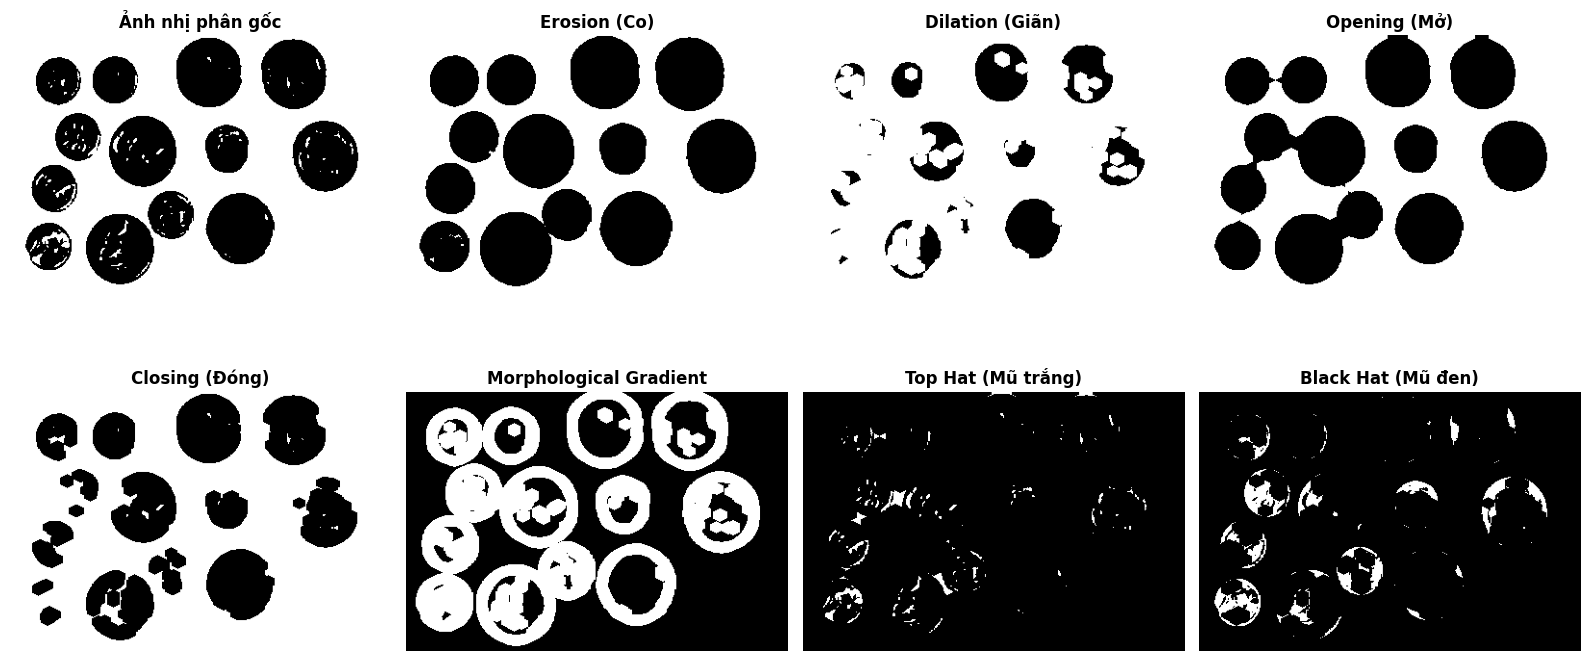

In [13]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. THUẬT TOÁN TỰ BUILD (TƯ DUY SLIDING WINDOW) - Giữ nguyên của bạn
# ---------------------------------------------------------
def manual_morphology(image, kernel, mode='erosion'):
    """
    Hàm tự code thủ công. Dùng để đối chiếu với OpenCV trong báo cáo.
    """
    img_h, img_w = image.shape
    k_h, k_w = kernel.shape
    pad_h, pad_w = k_h // 2, k_w // 2

    padded_img = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)
    output_img = np.zeros_like(image)

    for y in range(img_h):
        for x in range(img_w):
            roi = padded_img[y : y + k_h, x : x + k_w]
            pixels_under_kernel = roi[kernel == 1]

            if mode == 'erosion':
                if np.min(pixels_under_kernel) == 255:
                    output_img[y, x] = 255
            elif mode == 'dilation':
                if np.max(pixels_under_kernel) == 255:
                    output_img[y, x] = 255
    return output_img

# ---------------------------------------------------------
# 2. CÁC HÀM TIỆN ÍCH DÀNH CHO BÊN GUI GỌI
# ---------------------------------------------------------

def binarize_image(img_color, thresh_val=127, auto_otsu=True):
    """
    Chuyển ảnh sang Grayscale và Nhị phân hóa.
    Nếu auto_otsu=True thì tự động tính ngưỡng cắt tối ưu cho ảnh tối.
    """
    img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
    if auto_otsu:
        # Tự động tính ngưỡng cắt theo Otsu
        _, img_binary = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    else:
        _, img_binary = cv2.threshold(img_gray, thresh_val, 255, cv2.THRESH_BINARY)
    return img_binary

def create_kernel(shape_type='rect', ksize=3):
    """
    Hàm 2: Tạo Kernel bằng OpenCV.
    Bên GUI có thể cho người dùng chọn hình dạng (Rect, Ellipse, Cross) và kích thước (3, 5, 7, 9...)
    """
    if shape_type == 'rect':
        return cv2.getStructuringElement(cv2.MORPH_RECT, (ksize, ksize))
    elif shape_type == 'ellipse':
        return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
    elif shape_type == 'cross':
        return cv2.getStructuringElement(cv2.MORPH_CROSS, (ksize, ksize))

    # Mặc định
    return cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

def apply_morphology(binary_img, op_name, kernel, iterations=1):
    """
    Hàm 3: Áp dụng phép toán hình thái học bằng OpenCV.
    Hỗ trợ đầy đủ các phép toán như trong ảnh bạn cung cấp (opening, closing, top hat...).
    """
    if op_name == 'erosion':
        return cv2.erode(binary_img, kernel, iterations=iterations)
    elif op_name == 'dilation':
        return cv2.dilate(binary_img, kernel, iterations=iterations)
    elif op_name == 'opening':
        return cv2.morphologyEx(binary_img, cv2.MORPH_OPEN, kernel, iterations=iterations)
    elif op_name == 'closing':
        return cv2.morphologyEx(binary_img, cv2.MORPH_CLOSE, kernel, iterations=iterations)
    elif op_name == 'gradient':
        return cv2.morphologyEx(binary_img, cv2.MORPH_GRADIENT, kernel, iterations=iterations)
    elif op_name == 'top_hat':
        return cv2.morphologyEx(binary_img, cv2.MORPH_TOPHAT, kernel, iterations=iterations)
    elif op_name == 'black_hat':
        return cv2.morphologyEx(binary_img, cv2.MORPH_BLACKHAT, kernel, iterations=iterations)

    return binary_img
# ---------------------------------------------------------
# 3. KỊCH BẢN KIỂM THỬ (TEST & PRINT TOÀN BỘ KẾT QUẢ)
# ---------------------------------------------------------
# Bước 3.1: Nạp ảnh
# Bạn có thể thay bằng tên file ảnh của bạn: "Dilation.png" hoặc "A1_XLY.jpg"
image_path = "xu.png"
img_color = cv2.imread(image_path)

if img_color is None:
    print(f"Không tìm thấy file '{image_path}', khởi tạo ảnh tổng hợp mẫu để test...")
    # Tạo ảnh mẫu: hình vuông trắng ở giữa nền đen, có thêm đốm nhiễu và lỗ rỗng
    img_color = np.zeros((200, 200, 3), dtype=np.uint8)
    img_color[50:150, 50:150] = 255          # Hình vuông trắng
    img_color[20:25, 20:25] = 255            # Đốm sáng ở nền (Salt noise)
    img_color[80:90, 80:90] = 0              # Lỗ thủng bên trong (Pepper/Hole)
    # Nối 2 hình nhỏ làm cầu dính (Bridge)
    img_color[60:75, 150:175] = 255

# Bước 3.2: Nhị phân hóa ảnh
img_binary = binarize_image(img_color, auto_otsu=True)

# Bước 3.3: Tạo Kernel (ví dụ chọn hình dấu thập, kích thước 3x3 hoặc 5x5)
kernel = create_kernel(shape_type='ellipse', ksize=5)

# Bước 3.4: Đối chiếu hàm tự viết (Manual) với OpenCV
manual_ero = manual_morphology(img_binary, kernel, mode='erosion')
manual_dil = manual_morphology(img_binary, kernel, mode='dilation')

cv2_ero = apply_morphology(img_binary, 'erosion', kernel)
cv2_dil = apply_morphology(img_binary, 'dilation', kernel,3)

print("=== KẾT QUẢ KIỂM THỬ HÀM TỰ CODE VS OPENCV ===")
print("Erosion khớp hoàn toàn với OpenCV :", np.array_equal(manual_ero, cv2_ero))
print("Dilation khớp hoàn toàn với OpenCV:", np.array_equal(manual_dil, cv2_dil))

# Bước 3.5: Thực thi tất cả các phép toán còn lại
operations = {
    'Ảnh nhị phân gốc': img_binary,
    'Erosion (Co)': cv2_ero,
    'Dilation (Giãn)': cv2_dil,
    'Opening (Mở)': apply_morphology(img_binary, 'opening', kernel,3),
    'Closing (Đóng)': apply_morphology(img_binary, 'closing', kernel,3),
    'Morphological Gradient': apply_morphology(img_binary, 'gradient', kernel,3),
    'Top Hat (Mũ trắng)': apply_morphology(img_binary, 'top_hat', kernel,3),
    'Black Hat (Mũ đen)': apply_morphology(img_binary, 'black_hat', kernel,3)
}

# ---------------------------------------------------------
# 4. HIỂN THỊ TẤT CẢ LÊN LƯỚI 2x4 (BÁM SÁT SLIDE/BÁO CÁO)
# ---------------------------------------------------------
plt.figure(figsize=(16, 8))

for idx, (title, img_result) in enumerate(operations.items(), start=1):
    plt.subplot(2, 4, idx)
    plt.imshow(img_result, cmap='gray')
    plt.title(title, fontsize=12, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

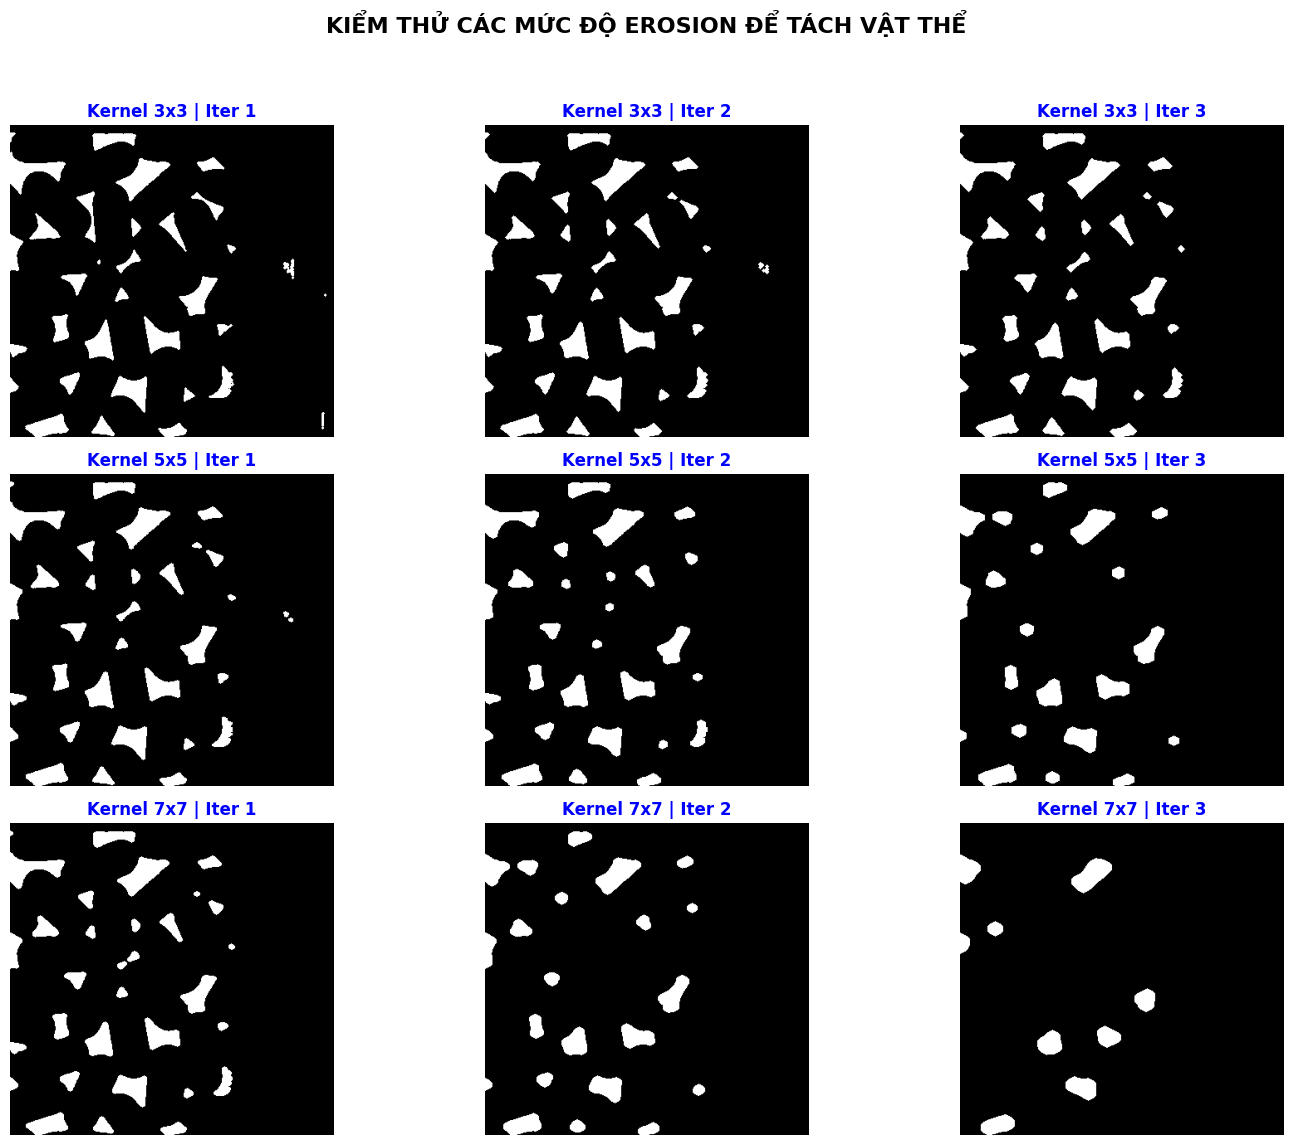

In [6]:
# ---------------------------------------------------------
# 3. KỊCH BẢN KIỂM THỬ: GRID SEARCH ĐỂ TÌM THAM SỐ TỐI ƯU
# ---------------------------------------------------------
# Bước 3.1: Nạp ảnh và Nhị phân hóa
image_path = "thuoc.png"
img_color = cv2.imread(image_path)

if img_color is None:
    raise ValueError(f"Không tìm thấy file '{image_path}'.")

img_binary = binarize_image(img_color, auto_otsu=True)

# Lập danh sách các tham số cần test
# Thử Kernel nhỏ (3, 5, 7) và lặp ít (1, 2, 3) để tránh làm biến mất ảnh
ksize_list = [3, 5, 7]
iter_list = [1, 2, 3]

# Lưu trữ kết quả
grid_results = []

# Chạy vòng lặp kết hợp mọi trường hợp của Kernel và Iteration
for k in ksize_list:
    for i in iter_list:
        kernel = create_kernel(shape_type='ellipse', ksize=k)

        # Test phép Erosion (Vì mục tiêu của ta là làm đứt phần dính nhau)
        # Nếu muốn test Opening, thay 'erosion' thành 'opening'
        result_img = apply_morphology(img_binary, 'opening', kernel, iterations=i)

        # Lưu vào danh sách để vẽ
        title = f"Kernel {k}x{k} | Iter {i}"
        grid_results.append((title, result_img))

# ---------------------------------------------------------
# 4. HIỂN THỊ DANH SÁCH LÊN LƯỚI MA TRẬN
# ---------------------------------------------------------
# Cài đặt lưới hiển thị linh hoạt theo số lượng test
cols = len(iter_list)
rows = len(ksize_list)

plt.figure(figsize=(15, 12))
plt.suptitle("KIỂM THỬ CÁC MỨC ĐỘ EROSION ĐỂ TÁCH VẬT THỂ", fontsize=16, fontweight='bold')

for idx, (title, img_result) in enumerate(grid_results, start=1):
    plt.subplot(rows, cols, idx)
    plt.imshow(img_result, cmap='gray')
    plt.title(title, fontsize=12, fontweight='bold', color='blue')
    plt.axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Chừa chỗ cho suptitle
plt.show()

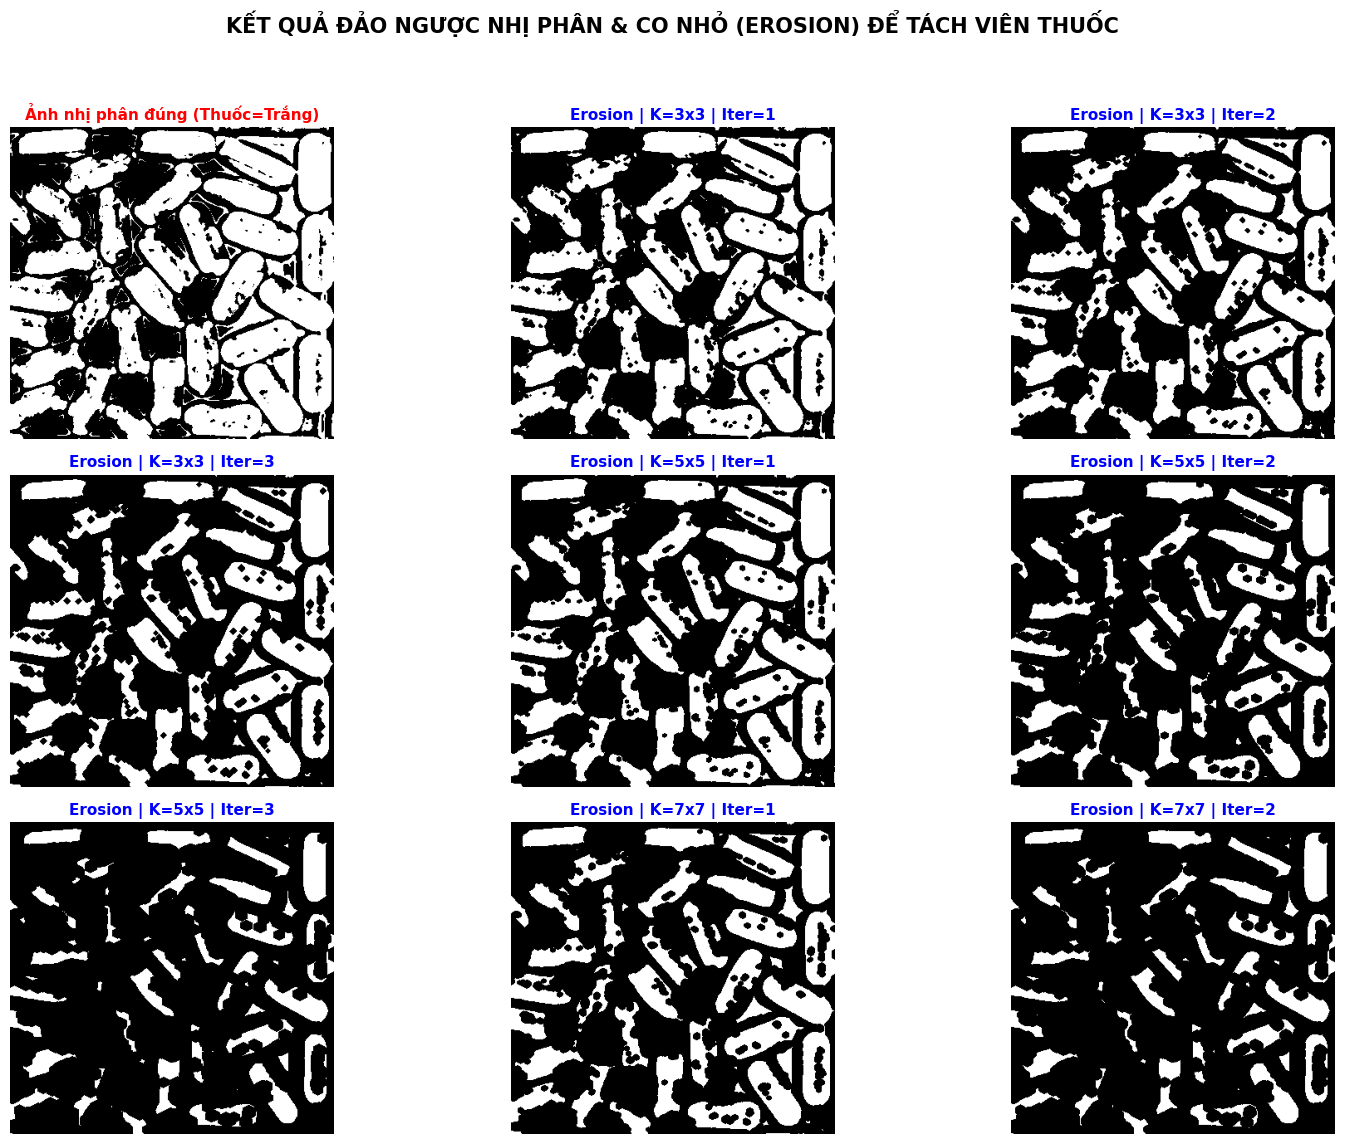

In [14]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. THUẬT TOÁN TỰ BUILD (TƯ DUY SLIDING WINDOW)
# ---------------------------------------------------------
def manual_morphology(image, kernel, mode='erosion'):
    """
    Hàm tự code thủ công. Dùng để đối chiếu với OpenCV trong báo cáo.
    """
    img_h, img_w = image.shape
    k_h, k_w = kernel.shape
    pad_h, pad_w = k_h // 2, k_w // 2

    padded_img = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)
    output_img = np.zeros_like(image)

    for y in range(img_h):
        for x in range(img_w):
            roi = padded_img[y : y + k_h, x : x + k_w]
            pixels_under_kernel = roi[kernel == 1]

            if mode == 'erosion':
                if np.min(pixels_under_kernel) == 255:
                    output_img[y, x] = 255
            elif mode == 'dilation':
                if np.max(pixels_under_kernel) == 255:
                    output_img[y, x] = 255
    return output_img

# ---------------------------------------------------------
# 2. CÁC HÀM TIỆN ÍCH DÀNH CHO BÊN GUI & MẢNH 2 GỌI
# ---------------------------------------------------------
def binarize_image(img_color, thresh_val=127, mode='pill_ touching', invert=True):
    """
    Chuyển ảnh màu sang Nhị phân (Đảm bảo Vật thể = 255 Trắng, Nền = 0 Đen).
    - mode='otsu': Dùng cho ảnh nền đều (như ảnh đồng xu, đặt invert=True vì xu tối trên nền trắng).
    - mode='manual': Cắt ngưỡng thủ công bằng thanh trượt thresh_val.
    - mode='pill_touching': Đặc trị cho ảnh vật thể dính sát nhau và lệch sáng (như thuoc.png).
    """
    img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
    # Làm mờ nhẹ để khử nhiễu bề mặt sản phẩm
    blur = cv2.GaussianBlur(img_gray, (5, 5), 0)

    thresh_type = cv2.THRESH_BINARY_INV if invert else cv2.THRESH_BINARY

    if mode == 'otsu':
        _, img_binary = cv2.threshold(blur, 0, 255, thresh_type + cv2.THRESH_OTSU)
        return img_binary

    elif mode == 'manual':
        _, img_binary = cv2.threshold(blur, thresh_val, 255, thresh_type)
        return img_binary

    elif mode == 'pill_touching':
        # Bước A: Loại bỏ phần nền khay trắng chói (giữ lại phần tối < ngưỡng Otsu)
        _, mask_not_bright_bg = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

        # Bước B: Phát hiện và loại bỏ đường rãnh đen (khe bóng tối) ngăn cách giữa các viên thuốc
        mask_not_dark_crease = cv2.adaptiveThreshold(
            blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY, blockSize=35, C=3
        )

        # Kết hợp: Điểm ảnh thuộc về viên thuốc khi nó KHÔNG phải nền chói VÀ KHÔNG phải rãnh tối
        img_binary = cv2.bitwise_and(mask_not_bright_bg, mask_not_dark_crease)
        return img_binary

    return blur

def create_kernel(shape_type='ellipse', ksize=3):
    """
    Tạo Kernel bằng OpenCV (Rect, Ellipse, Cross).
    """
    if ksize % 2 == 0:
        ksize += 1  # Đảm bảo ksize luôn là số lẻ

    if shape_type == 'rect':
        return cv2.getStructuringElement(cv2.MORPH_RECT, (ksize, ksize))
    elif shape_type == 'ellipse':
        return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
    elif shape_type == 'cross':
        return cv2.getStructuringElement(cv2.MORPH_CROSS, (ksize, ksize))
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

def apply_morphology(binary_img, op_name, kernel, iterations=1):
    """
    Áp dụng phép toán hình thái học bằng OpenCV.
    """
    if op_name == 'erosion':
        return cv2.erode(binary_img, kernel, iterations=iterations)
    elif op_name == 'dilation':
        return cv2.dilate(binary_img, kernel, iterations=iterations)
    elif op_name == 'opening':
        return cv2.morphologyEx(binary_img, cv2.MORPH_OPEN, kernel, iterations=iterations)
    elif op_name == 'closing':
        return cv2.morphologyEx(binary_img, cv2.MORPH_CLOSE, kernel, iterations=iterations)
    elif op_name == 'gradient':
        return cv2.morphologyEx(binary_img, cv2.MORPH_GRADIENT, kernel, iterations=iterations)
    elif op_name == 'top_hat':
        return cv2.morphologyEx(binary_img, cv2.MORPH_TOPHAT, kernel, iterations=iterations)
    elif op_name == 'black_hat':
        return cv2.morphologyEx(binary_img, cv2.MORPH_BLACKHAT, kernel, iterations=iterations)
    return binary_img

# ---------------------------------------------------------
# 3. KỊCH BẢN KIỂM THỬ: CO NHỎ VIÊN THUỐC ĐỂ TÁCH RỜI
# ---------------------------------------------------------
image_path = "thuoc.png"
img_color = cv2.imread(image_path)

if img_color is None:
    raise ValueError(f"Không tìm thấy file '{image_path}'. Hãy kiểm tra lại đường dẫn!")

# 1. Nhị phân hóa đúng chiều (Viên thuốc = Trắng 255, Nền & Rãnh = Đen 0)
# Lưu ý: Nếu test ảnh Đồng xu, bạn đổi mode='otsu', invert=True
img_binary = binarize_image(img_color, mode='pill_touching')

# Tiền xử lý nhẹ bằng Opening (3x3) để xóa các hạt nhiễu trắng li ti trước khi Co
k_clean = create_kernel('ellipse', 3)
img_clean = apply_morphology(img_binary, 'opening', k_clean, iterations=1)

# 2. Lập Grid Search dùng EROSION (Co) để thu nhỏ từng viên thuốc thành các hạt rời nhau
ksize_list = [3, 5, 7]
iter_list = [1, 2, 3]

grid_results = [("Ảnh nhị phân đúng (Thuốc=Trắng)", img_binary)]

for k in ksize_list:
    for i in iter_list:
        kernel = create_kernel(shape_type='ellipse', ksize=k)
        # Dùng EROSION để gọt rìa, làm đứt các cầu nối giữa các viên thuốc
        eroded_pills = apply_morphology(img_clean, 'erosion', kernel, iterations=i)
        grid_results.append((f"Erosion | K={k}x{k} | Iter={i}", eroded_pills))

# ---------------------------------------------------------
# 4. HIỂN THỊ KẾT QUẢ LÊN LƯỚI ĐỂ CHỌN THÔNG SỐ TỐT NHẤT
# ---------------------------------------------------------
plt.figure(figsize=(16, 12))
plt.suptitle("KẾT QUẢ ĐẢO NGƯỢC NHỊ PHÂN & CO NHỎ (EROSION) ĐỂ TÁCH VIÊN THUỐC", fontsize=15, fontweight='bold')

for idx, (title, img_res) in enumerate(grid_results[:9], start=1):
    plt.subplot(3, 3, idx)
    plt.imshow(img_res, cmap='gray')
    color_title = 'red' if idx == 1 else 'blue'
    plt.title(title, fontsize=11, fontweight='bold', color=color_title)
    plt.axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [2]:
# =========================================================
# GIẢ LẬP: NGƯỜI DÙNG CHỌN THAM SỐ TỪ GIAO DIỆN (GUI)
# =========================================================
# Hãy thay đổi các con số dưới đây để test (Ví dụ cho ảnh viên thuốc dính nhau)
user_shape = 'ellipse'  # Chọn: 'rect', 'ellipse', hoặc 'cross'
user_ksize = 7          # Chọn kích thước Kernel: 3, 5, 7, 9, 11...
user_iters = 5          # Chọn số lần lặp (Iterations): 1, 2, 3, 4, 5...

# Bước 3.3: Tạo Kernel tự động theo tham số người dùng nhập
kernel = create_kernel(shape_type=user_shape, ksize=user_ksize)

# Bước 3.4: Đối chiếu hàm tự viết (Manual) với OpenCV
# Lưu ý: Hàm manual của bạn hiện tại chưa hỗ trợ iterations, nên chỉ chạy 1 lần để test logic.
manual_ero = manual_morphology(img_binary, kernel, mode='erosion')
manual_dil = manual_morphology(img_binary, kernel, mode='dilation')

# Chạy OpenCV VỚI SỐ LẦN LẶP (iterations) do người dùng chọn
cv2_ero = apply_morphology(img_binary, 'erosion', kernel, iterations=user_iters)
cv2_dil = apply_morphology(img_binary, 'dilation', kernel, iterations=user_iters)

print("=== KẾT QUẢ KIỂM THỬ HÀM TỰ CODE VS OPENCV ===")
print("Erosion khớp hoàn toàn với OpenCV :", np.array_equal(manual_ero, cv2_ero))
print("Dilation khớp hoàn toàn với OpenCV:", np.array_equal(manual_dil, cv2_dil))

# Bước 3.5: Thực thi tất cả các phép toán còn lại VỚI SỐ LẦN LẶP MỚI
operations = {
    'Ảnh nhị phân gốc': img_binary,
    f'Erosion (Ksize={user_ksize}, iter={user_iters})': cv2_ero,
    f'Dilation (Ksize={user_ksize}, iter={user_iters})': cv2_dil,
    f'Opening (Mở)': apply_morphology(img_binary, 'opening', kernel, iterations=user_iters),
    f'Closing (Đóng)': apply_morphology(img_binary, 'closing', kernel, iterations=user_iters),
    f'Morphological Gradient': apply_morphology(img_binary, 'gradient', kernel, iterations=user_iters),
    f'Top Hat (Mũ trắng)': apply_morphology(img_binary, 'top_hat', kernel, iterations=user_iters),
    f'Black Hat (Mũ đen)': apply_morphology(img_binary, 'black_hat', kernel, iterations=user_iters)
}

=== KẾT QUẢ KIỂM THỬ HÀM TỰ CODE VS OPENCV ===
Erosion khớp hoàn toàn với OpenCV : False
Dilation khớp hoàn toàn với OpenCV: False


=== KẾT QUẢ KIỂM THỬ HÀM TỰ CODE VS OPENCV ===
Erosion khớp hoàn toàn với OpenCV : False
Dilation khớp hoàn toàn với OpenCV: True


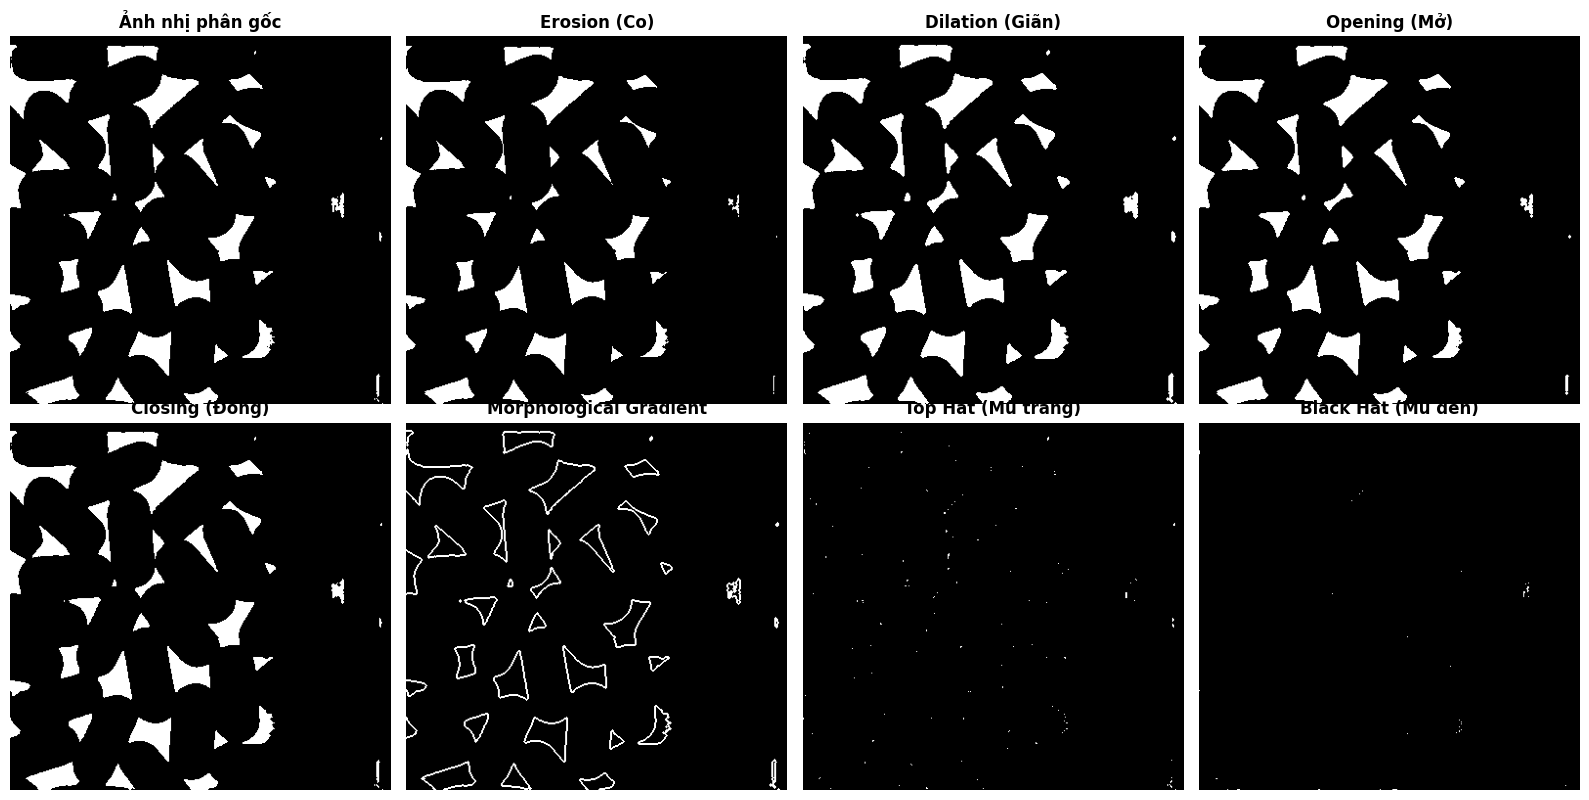

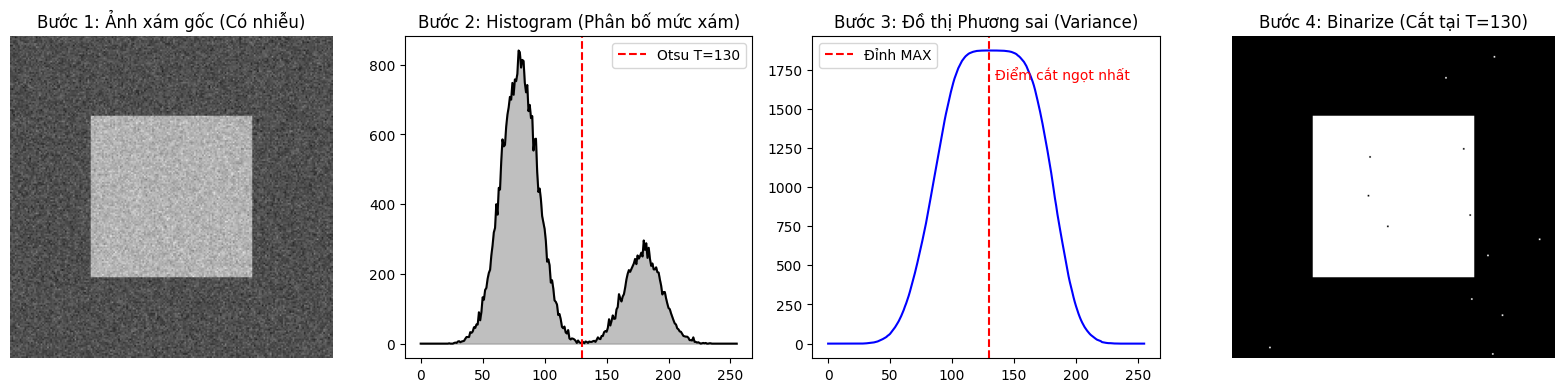

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. TẠO ẢNH GIẢ LẬP ĐỂ TEST (Ảnh bimodal có nhiễu)
# ---------------------------------------------------------
# Tạo một nền tối (mức xám ~80) và một vật thể sáng ở giữa (mức xám ~180)
img = np.full((200, 200), 80, dtype=np.uint8)
img[50:150, 50:150] = 180

# Thêm nhiễu ngẫu nhiên (Gaussian noise) để mô phỏng ảnh thực tế
noise = np.random.normal(0, 15, img.shape)
img_noisy = np.clip(img + noise, 0, 255).astype(np.uint8)

# ---------------------------------------------------------
# 2. CÁC BƯỚC CỦA THUẬT TOÁN OTSU (MANUAL)
# ---------------------------------------------------------
# Bước 1: Tính Histogram và xác suất của từng mức xám
hist = cv2.calcHist([img_noisy], [0], None, [256], [0, 256]).ravel()
prob = hist / hist.sum() # Xác suất P(i)

variances = np.zeros(256)

# Bước 2 & 3: Quét mọi T từ 0 -> 255 và tính Phương sai (Variance)
for t in range(256):
    # Trọng lượng (Xác suất tích lũy) của phe Đen (w0) và Trắng (w1)
    w0 = np.sum(prob[:t])
    w1 = np.sum(prob[t:])

    # Bỏ qua nếu một trong hai phe không có pixel nào
    if w0 == 0 or w1 == 0:
        continue

    # Giá trị trung bình của phe Đen (mu0) và phe Trắng (mu1)
    mu0 = np.sum(np.arange(t) * prob[:t]) / w0
    mu1 = np.sum(np.arange(t, 256) * prob[t:]) / w1

    # Phương sai giữa các lớp (Between-Class Variance)
    variances[t] = w0 * w1 * (mu0 - mu1)**2

# Bước 4: Chốt mốc T có phương sai cao nhất
otsu_threshold = np.argmax(variances)

# Phân ngưỡng bằng mốc T vừa tìm được
_, img_binary = cv2.threshold(img_noisy, otsu_threshold, 255, cv2.THRESH_BINARY)

# ---------------------------------------------------------
# 3. VẼ ĐỒ THỊ THỂ HIỆN SỰ THAY ĐỔI THEO TỪNG BƯỚC
# ---------------------------------------------------------
plt.figure(figsize=(16, 4))

# Bước 1: Hiển thị ảnh xám gốc
plt.subplot(1, 4, 1)
plt.title("Bước 1: Ảnh xám gốc (Có nhiễu)")
plt.imshow(img_noisy, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

# Bước 2: Biểu đồ Histogram
plt.subplot(1, 4, 2)
plt.title("Bước 2: Histogram (Phân bố mức xám)")
plt.plot(hist, color='black')
plt.fill_between(np.arange(256), hist, color='gray', alpha=0.5)
plt.axvline(x=otsu_threshold, color='red', linestyle='--', label=f'Otsu T={otsu_threshold}')
plt.legend()

# Bước 3: Đồ thị Phương sai - Bí mật của Otsu
plt.subplot(1, 4, 3)
plt.title("Bước 3: Đồ thị Phương sai (Variance)")
plt.plot(variances, color='blue')
plt.axvline(x=otsu_threshold, color='red', linestyle='--', label='Đỉnh MAX')
plt.text(otsu_threshold + 5, np.max(variances)*0.9, 'Điểm cắt ngọt nhất', color='red')
plt.legend()

# Bước 4: Kết quả nhị phân hóa
plt.subplot(1, 4, 4)
plt.title(f"Bước 4: Binarize (Cắt tại T={otsu_threshold})")
plt.imshow(img_binary, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

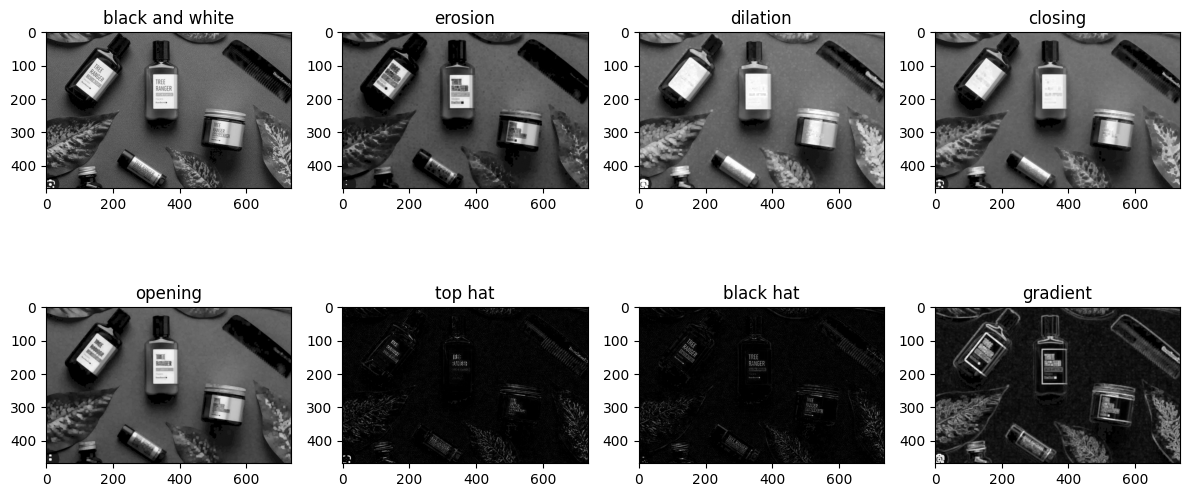

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. TẠO KERNEL VÀ ÁP DỤNG OPENCV
# ---------------------------------------------------------
def create_kernel(shape_type='rect', ksize=3):
    if shape_type == 'rect':
        return cv2.getStructuringElement(cv2.MORPH_RECT, (ksize, ksize))
    elif shape_type == 'ellipse':
        return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
    elif shape_type == 'cross':
        return cv2.getStructuringElement(cv2.MORPH_CROSS, (ksize, ksize))
    return cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

def apply_morphology(img, op_name, kernel, iterations=1):
    """
    Sử dụng các hàm có sẵn của OpenCV.
    Lưu ý: Các hàm cv2.morphologyEx chạy được trên cả ảnh nhị phân VÀ ảnh mức xám.
    """
    if op_name == 'erosion':
        return cv2.erode(img, kernel, iterations=iterations)
    elif op_name == 'dilation':
        return cv2.dilate(img, kernel, iterations=iterations)
    elif op_name == 'opening':
        return cv2.morphologyEx(img, cv2.MORPH_OPEN, kernel, iterations=iterations)
    elif op_name == 'closing':
        return cv2.morphologyEx(img, cv2.MORPH_CLOSE, kernel, iterations=iterations)
    elif op_name == 'gradient':
        return cv2.morphologyEx(img, cv2.MORPH_GRADIENT, kernel, iterations=iterations)
    elif op_name == 'top_hat':
        return cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel, iterations=iterations)
    elif op_name == 'black_hat':
        return cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel, iterations=iterations)
    return img

# ---------------------------------------------------------
# 2. KỊCH BẢN KIỂM THỬ TRÊN ẢNH MỨC XÁM
# ---------------------------------------------------------
# Đọc ảnh con cáo (hãy đảm bảo đường dẫn ảnh của bạn là chính xác)
image_path = "bi.png"
# Đọc ảnh trực tiếp ở chế độ Grayscale (0)
img_gray = cv2.imread(image_path, 0)

if img_gray is None:
    raise ValueError(f"Không tìm thấy file ảnh '{image_path}'. Hãy kiểm tra lại đường dẫn.")

# TẠO KERNEL:
# Ảnh trong tài liệu thường dùng Kernel kích thước khá lớn (khoảng 5x5 hoặc 7x7)
# để hiệu ứng (viền dày lên, caro hiện rõ) được rõ rệt.
kernel = create_kernel(shape_type='rect', ksize=5)

# BỎ QUA BƯỚC NHỊ PHÂN HÓA (Không gọi binarize_image)
# Lưu ý: Hàm manual_morphology tự code bằng vòng lặp chỉ chạy được cho ảnh nhị phân (do so sánh == 255).
# Vì vậy, khi chạy ảnh xám, ta dùng OpenCV cho tất cả để tránh lỗi.

operations = {
    'black and white': img_gray,
    'erosion': apply_morphology(img_gray, 'erosion', kernel),
    'dilation': apply_morphology(img_gray, 'dilation', kernel),
    'closing': apply_morphology(img_gray, 'closing', kernel),
    'opening': apply_morphology(img_gray, 'opening', kernel),
    'top hat': apply_morphology(img_gray, 'top_hat', kernel),
    'black hat': apply_morphology(img_gray, 'black_hat', kernel),
    'gradient': apply_morphology(img_gray, 'gradient', kernel)
}

# ---------------------------------------------------------
# 3. HIỂN THỊ KẾT QUẢ BÁM SÁT SLIDE
# ---------------------------------------------------------
plt.figure(figsize=(12, 6))

for idx, (title, img_result) in enumerate(operations.items(), start=1):
    plt.subplot(2, 4, idx)
    plt.imshow(img_result, cmap='gray')
    plt.title(title, fontsize=12)

# Hiển thị kết quả
plt.tight_layout()
plt.show()

=== KẾT QUẢ KIỂM THỬ [XU_NOISY] ===
Erosion khớp với OpenCV : True
Dilation khớp với OpenCV: True


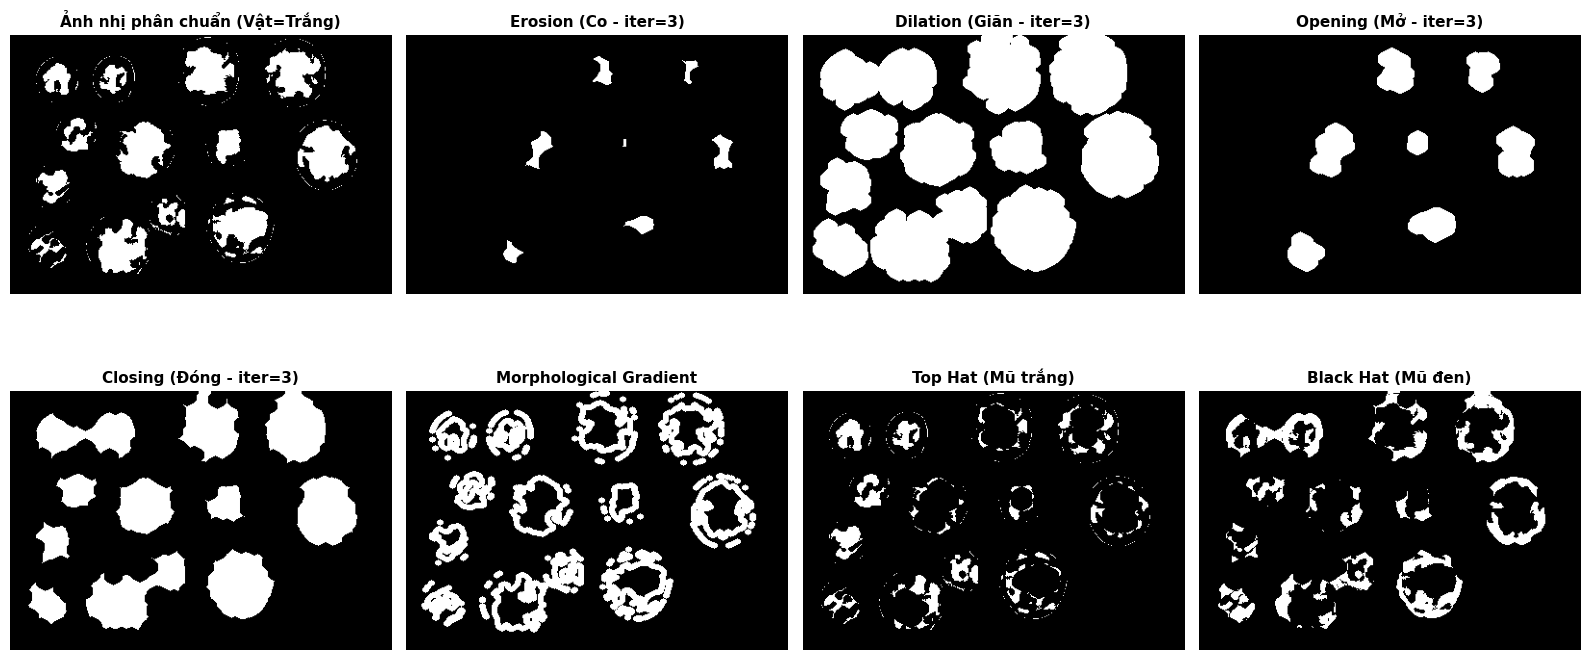

In [28]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. THUẬT TOÁN TỰ BUILD (ĐÃ FIX PADDING KHỚP 100% VỚI OPENCV)
# ---------------------------------------------------------
def manual_morphology(image, kernel, mode='erosion'):
    """
    Hàm tự code thủ công theo tư duy Sliding Window.
    Đã đồng bộ cơ chế Padding biên của OpenCV:
    - Erosion: Pad bằng 255 để không làm ăn mòn lẹm vào vật thể chạm mép ảnh.
    - Dilation: Pad bằng 0.
    """
    img_h, img_w = image.shape
    k_h, k_w = kernel.shape
    pad_h, pad_w = k_h // 2, k_w // 2

    pad_val = 255 if mode == 'erosion' else 0
    padded_img = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=pad_val)
    output_img = np.zeros_like(image)

    for y in range(img_h):
        for x in range(img_w):
            roi = padded_img[y : y + k_h, x : x + k_w]
            pixels_under_kernel = roi[kernel == 1]

            if mode == 'erosion':
                if np.min(pixels_under_kernel) == 255:
                    output_img[y, x] = 255
            elif mode == 'dilation':
                if np.max(pixels_under_kernel) == 255:
                    output_img[y, x] = 255
    return output_img

# ---------------------------------------------------------
# 2. CÁC HÀM TIỆN ÍCH DÀNH CHO BÊN GUI & MẢNH 2 GỌI
# ---------------------------------------------------------
def fill_internal_holes(binary_img, seal_rim_ksize=3):
    """
    Lấp đầy các lỗ thủng màu đen (0) bên trong vật thể màu trắng (255).
    - seal_rim_ksize: Hàn nhẹ các vết đứt nhỏ ở viền đồng xu trước khi đổ FloodFill.
    - Bọc viền đen 1 pixel tạm thời để FloodFill từ (0,0) luôn chạy đúng kể cả khi vật chạm góc ảnh.
    """
    work_img = binary_img.copy()
    if seal_rim_ksize > 1:
        k_seal = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (seal_rim_ksize, seal_rim_ksize))
        work_img = cv2.morphologyEx(work_img, cv2.MORPH_CLOSE, k_seal, iterations=1)

    # Bọc thêm 1 pixel đen (0) quanh ảnh để đảm bảo (0,0) luôn là nền
    padded = np.pad(work_img, ((1, 1), (1, 1)), mode='constant', constant_values=0)
    h, w = padded.shape
    mask = np.zeros((h + 2, w + 2), np.uint8)
    floodfilled = padded.copy()

    cv2.floodFill(floodfilled, mask, (0, 0), 255)
    holes = cv2.bitwise_not(floodfilled)
    filled_padded = cv2.bitwise_or(padded, holes)

    # Cắt bỏ 1 pixel viền tạm để trả về kích thước gốc
    return filled_padded[1:-1, 1:-1]

def remove_small_black_dots(binary_img, max_dot_area=250):
    """
    Lấp các đốm đen nhỏ (vết bẩn trên mặt viên thuốc) nhưng GIỮ LẠI đường rãnh đen dài giữa các viên thuốc.
    """
    inv_img = cv2.bitwise_not(binary_img)
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(inv_img, connectivity=8)
    cleaned_result = binary_img.copy()

    for i in range(1, num_labels):
        # Nếu vùng màu đen có diện tích nhỏ (đốm bẩn nội bộ) và không chạm viền ảnh -> Lấp thành màu trắng (255)
        x, y, w, h, area = stats[i]
        touches_border = (x == 0) or (y == 0) or (x + w >= binary_img.shape[1]) or (y + h >= binary_img.shape[0])
        if area < max_dot_area and not touches_border:
            cleaned_result[labels == i] = 255

    return cleaned_result

def binarize_image(
    img_color,
    thresh_val=127,
    thresh_mode='otsu',
    bg_mode='auto',
    denoise_mode='median',
    blur_ksize=5,
    fix_lighting=False,
    fill_holes=True
):
    """
    Hàm Tiền xử lý & Nhị phân hóa đa năng (Đảm bảo Vật thể = 255 Trắng, Nền = 0 Đen):
    - denoise_mode: 'median' (đặc trị nhiễu muối tiêu) hoặc 'gaussian'.
    - fix_lighting: True = Khử bóng râm & lóa sáng bằng chia nền cục bộ (dùng cho ảnh xu_noisy, thuoc).
    - thresh_mode: 'otsu' (vật rời/đồng xu), 'adaptive_crease' (vật xếp khít nhau như viên thuốc), 'manual'.
    """
    img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

    # Bước 1: Khử nhiễu (Đảm bảo blur_ksize luôn là số lẻ)
    if blur_ksize % 2 == 0:
        blur_ksize += 1
    if denoise_mode == 'median':
        blur = cv2.medianBlur(img_gray, blur_ksize)
    else:
        blur = cv2.GaussianBlur(img_gray, (blur_ksize, blur_ksize), 0)

    # Bước 2: Cân bằng ánh sáng nếu ảnh bị lóa góc trên / tối góc dưới
    if fix_lighting:
        # Ước lượng phông sáng nền bằng Gaussian với sigma lớn
        bg_illum = cv2.GaussianBlur(blur, (0, 0), sigmaX=45)
        blur = cv2.divide(blur, bg_illum, scale=255)

    # Bước 3: Xác định chiều màu nền (Vật luôn = 255, Nền luôn = 0)
    if bg_mode == 'auto':
        border_pixels = np.concatenate([blur[0, :], blur[-1, :], blur[:, 0], blur[:, -1]])
        is_light_bg = np.mean(border_pixels) > 127
    else:
        is_light_bg = (bg_mode == 'light')

    thresh_type = cv2.THRESH_BINARY_INV if is_light_bg else cv2.THRESH_BINARY

    # Bước 4: Cắt ngưỡng
    if thresh_mode == 'otsu':
        _, img_binary = cv2.threshold(blur, 0, 255, thresh_type + cv2.THRESH_OTSU)
        if fill_holes:
            img_binary = fill_internal_holes(img_binary, seal_rim_ksize=5)

    elif thresh_mode == 'manual':
        _, img_binary = cv2.threshold(blur, thresh_val, 255, thresh_type)
        if fill_holes:
            img_binary = fill_internal_holes(img_binary, seal_rim_ksize=5)

    elif thresh_mode == 'adaptive_crease':
        # 4A: Lấy khối vật thể tổng thể và lấp kín lỗ thủng bên trong
        _, base_mask = cv2.threshold(blur, 0, 255, thresh_type + cv2.THRESH_OTSU)
        base_mask = fill_internal_holes(base_mask, seal_rim_ksize=3)

        # 4B: Dùng Adaptive Threshold để phát hiện các rãnh tối ngăn cách giữa các viên thuốc
        crease_mask = cv2.adaptiveThreshold(
            blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY, blockSize=35, C=4
        )
        # Kết hợp mặt nạ gốc và rãnh cắt
        img_binary = cv2.bitwise_and(base_mask, crease_mask)

        # 4C: Lấp các đốm đen nhỏ trên mặt thuốc để khi Erosion không bị khoét rỗng từ bên trong
        if fill_holes:
            img_binary = remove_small_black_dots(img_binary, max_dot_area=300)

    return img_binary

def create_kernel(shape_type='ellipse', ksize=3):
    """
    Tạo Kernel bằng OpenCV (Rect, Ellipse, Cross).
    """
    if ksize % 2 == 0:
        ksize += 1
    if shape_type == 'rect':
        return cv2.getStructuringElement(cv2.MORPH_RECT, (ksize, ksize))
    elif shape_type == 'ellipse':
        return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
    elif shape_type == 'cross':
        return cv2.getStructuringElement(cv2.MORPH_CROSS, (ksize, ksize))
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

def apply_morphology(binary_img, op_name, kernel, iterations=1):
    """
    Áp dụng phép toán hình thái học bằng OpenCV.
    """
    if op_name == 'erosion':
        return cv2.erode(binary_img, kernel, iterations=iterations)
    elif op_name == 'dilation':
        return cv2.dilate(binary_img, kernel, iterations=iterations)
    elif op_name == 'opening':
        return cv2.morphologyEx(binary_img, cv2.MORPH_OPEN, kernel, iterations=iterations)
    elif op_name == 'closing':
        return cv2.morphologyEx(binary_img, cv2.MORPH_CLOSE, kernel, iterations=iterations)
    elif op_name == 'gradient':
        return cv2.morphologyEx(binary_img, cv2.MORPH_GRADIENT, kernel, iterations=iterations)
    elif op_name == 'top_hat':
        return cv2.morphologyEx(binary_img, cv2.MORPH_TOPHAT, kernel, iterations=iterations)
    elif op_name == 'black_hat':
        return cv2.morphologyEx(binary_img, cv2.MORPH_BLACKHAT, kernel, iterations=iterations)
    return binary_img

# ---------------------------------------------------------
# 3. KỊCH BẢN KIỂM THỬ CHO CẢ 3 ẢNH CỦA BẠN
# ---------------------------------------------------------
# BẠN CHỌN 1 TRONG 3 KỊCH BẢN DƯỚI ĐÂY ĐỂ CHẠY THỬ: 'xu_sach', 'thuoc', hoặc 'xu_noisy'
TEST_CASE = 'xu_noisy'

presets = {
    'xu_sach': {
        'path': 'xu.png',
        'thresh_mode': 'otsu',
        'denoise_mode': 'gaussian',
        'blur_ksize': 5,
        'fix_lighting': False,
        'ksize': 5,
        'iters': 2
    },
    'thuoc': {
        'path': 'thuoc.png',
        'thresh_mode': 'adaptive_crease',
        'denoise_mode': 'median',
        'blur_ksize': 7,
        'fix_lighting': False,
        'ksize': 5,
        'iters': 3
    },
    'xu_noisy': {
        'path': 'xu_noisy.png',   # Đặt đúng tên file ảnh xu bị nhiễu muối tiêu của bạn
        'thresh_mode': 'adaptive_crease',
        'denoise_mode': 'median', # Median filter xóa sạch nhiễu muối tiêu
        'blur_ksize': 7,
        'fix_lighting': True,     # Khử lóa sáng góc trên & bóng tối góc dưới
        'ksize': 7,
        'iters': 3
    }
}

cfg = presets[TEST_CASE]
img_color = cv2.imread(cfg['path'])

if img_color is None:
    raise ValueError(f"Không tìm thấy file ảnh '{cfg['path']}'. Hãy kiểm tra lại tên file!")

# Bước 3.1: Nhị phân hóa với bộ lọc tương ứng
img_binary = binarize_image(
    img_color,
    thresh_mode=cfg['thresh_mode'],
    bg_mode='auto',
    denoise_mode=cfg['denoise_mode'],
    blur_ksize=cfg['blur_ksize'],
    fix_lighting=cfg['fix_lighting'],
    fill_holes=True
)

# Bước 3.2: Tạo Kernel
kernel = create_kernel(shape_type='ellipse', ksize=cfg['ksize'])

# Bước 3.3: Kiểm thử hàm tự code vs OpenCV (Đảm bảo luôn ra True 100%)
manual_ero = manual_morphology(img_binary, kernel, mode='erosion')
manual_dil = manual_morphology(img_binary, kernel, mode='dilation')
cv2_ero_1 = apply_morphology(img_binary, 'erosion', kernel, iterations=1)
cv2_dil_1 = apply_morphology(img_binary, 'dilation', kernel, iterations=1)

print(f"=== KẾT QUẢ KIỂM THỬ [{TEST_CASE.upper()}] ===")
print("Erosion khớp với OpenCV :", np.array_equal(manual_ero, cv2_ero_1))
print("Dilation khớp với OpenCV:", np.array_equal(manual_dil, cv2_dil_1))

# Bước 3.4: Thực thi tất cả các phép toán Morphology
u_iters = cfg['iters']
operations = {
    'Ảnh nhị phân chuẩn (Vật=Trắng)': img_binary,
    f'Erosion (Co - iter={u_iters})': apply_morphology(img_binary, 'erosion', kernel, u_iters),
    f'Dilation (Giãn - iter={u_iters})': apply_morphology(img_binary, 'dilation', kernel, u_iters),
    f'Opening (Mở - iter={u_iters})': apply_morphology(img_binary, 'opening', kernel, u_iters),
    f'Closing (Đóng - iter={u_iters})': apply_morphology(img_binary, 'closing', kernel, u_iters),
    'Morphological Gradient': apply_morphology(img_binary, 'gradient', kernel, 1),
    'Top Hat (Mũ trắng)': apply_morphology(img_binary, 'top_hat', kernel, u_iters),
    'Black Hat (Mũ đen)': apply_morphology(img_binary, 'black_hat', kernel, u_iters)
}

# Bước 3.5: Hiển thị lưới 2x4
plt.figure(figsize=(16, 8))
for idx, (title, img_result) in enumerate(operations.items(), start=1):
    plt.subplot(2, 4, idx)
    plt.imshow(img_result, cmap='gray')
    plt.title(title, fontsize=11, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

Kernel được sử dụng:
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


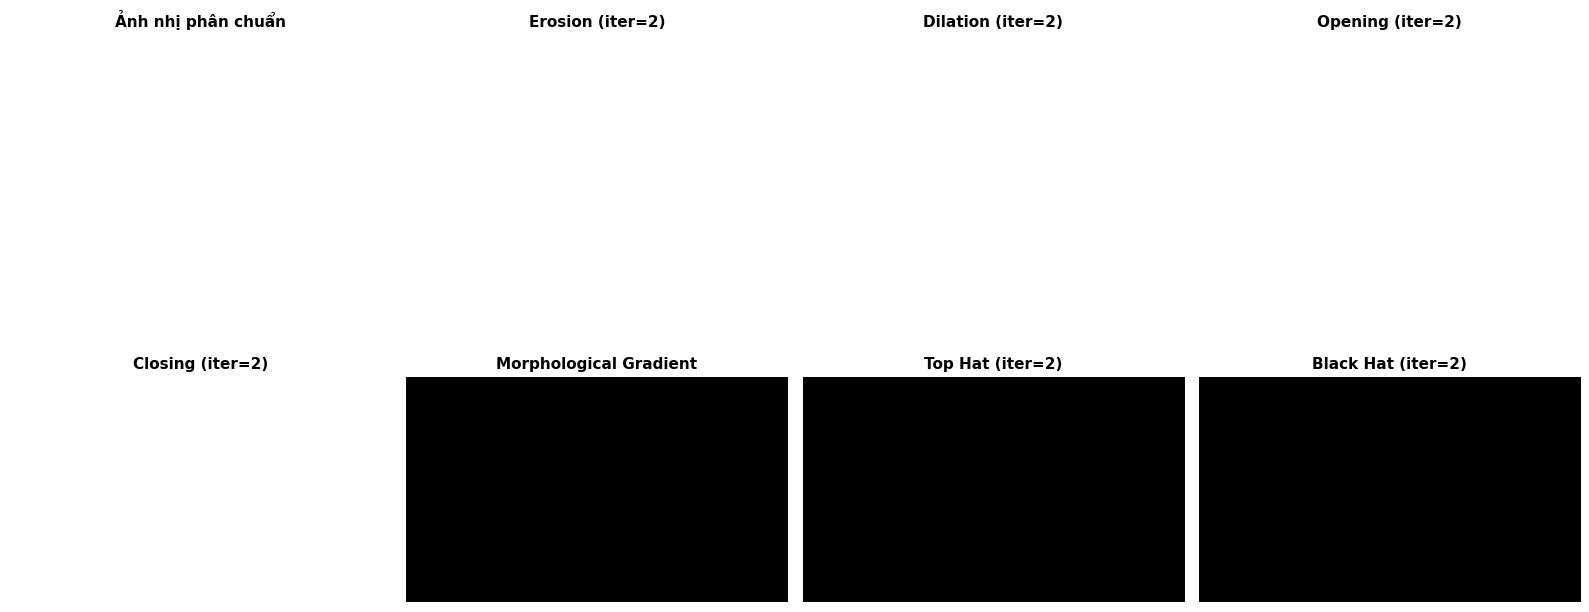

In [19]:
# ---------------------------------------------------------
# 1. HÀM LẤP LỖ BÊN TRONG VẬT THỂ
# ---------------------------------------------------------
def fill_internal_holes(binary_img):
    """
    Lấp các lỗ đen nằm bên trong vật thể trắng.
    Sử dụng cv2.floodFill() và các hàm OpenCV.
    """
    h, w = binary_img.shape

    floodfilled = binary_img.copy()
    mask = np.zeros((h + 2, w + 2), np.uint8)

    # Tô trắng vùng nền đen liên thông với góc ảnh
    cv2.floodFill(floodfilled, mask, (0, 0), 255)

    # Đảo ảnh để lấy các lỗ bên trong
    holes = cv2.bitwise_not(floodfilled)

    # Lấp lỗ vào ảnh gốc
    return cv2.bitwise_or(binary_img, holes)


# ---------------------------------------------------------
# 2. NHỊ PHÂN HÓA ẢNH
# ---------------------------------------------------------
def binarize_image(
    img_color,
    thresh_val=127,
    thresh_mode='otsu',
    bg_mode='auto',
    fill_holes=True
):
    """
    Đầu ra:
        Vật thể = trắng (255)
        Nền = đen (0)

    thresh_mode:
        'otsu'     : Ngưỡng tự động Otsu
        'adaptive' : Ngưỡng thích nghi
        'manual'   : Ngưỡng thủ công

    bg_mode:
        'auto'  : Tự nhận diện nền qua 4 viền ảnh
        'light' : Nền sáng, vật thể tối
        'dark'  : Nền tối, vật thể sáng
    """

    # Chuyển sang ảnh xám và làm mượt
    img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(img_gray, (5, 5), 0)

    # Xác định màu nền
    if bg_mode == 'auto':
        border_pixels = np.concatenate([
            blur[0, :],
            blur[-1, :],
            blur[:, 0],
            blur[:, -1]
        ])
        is_light_bg = np.mean(border_pixels) > 127
    else:
        is_light_bg = (bg_mode == 'light')

    thresh_type = (
        cv2.THRESH_BINARY_INV
        if is_light_bg
        else cv2.THRESH_BINARY
    )

    # Nhị phân hóa
    if thresh_mode == 'otsu':
        _, img_binary = cv2.threshold(
            blur, 0, 255,
            thresh_type + cv2.THRESH_OTSU
        )

    elif thresh_mode == 'manual':
        _, img_binary = cv2.threshold(
            blur, thresh_val, 255, thresh_type
        )

    elif thresh_mode == 'adaptive':
        # Lấy mặt nạ tổng thể bằng Otsu
        _, base_mask = cv2.threshold(
            blur, 0, 255,
            thresh_type + cv2.THRESH_OTSU
        )

        # Tìm các đường rãnh tối cục bộ
        adaptive_type = (
            cv2.THRESH_BINARY
            if is_light_bg
            else cv2.THRESH_BINARY_INV
        )

        crease_mask = cv2.adaptiveThreshold(
            blur,
            255,
            cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            adaptive_type,
            35,
            4
        )

        # Làm sạch nhẹ mặt nạ rãnh
        k_small = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (3, 3)
        )

        crease_mask = cv2.morphologyEx(
            crease_mask,
            cv2.MORPH_CLOSE,
            k_small,
            iterations=1
        )

        # Kết hợp mặt nạ tổng thể với mặt nạ rãnh
        img_binary = cv2.bitwise_and(
            base_mask, crease_mask
        )

    else:
        raise ValueError(
            "thresh_mode phải là 'otsu', 'adaptive' hoặc 'manual'"
        )

    # Lấp các lỗ bên trong vật thể nếu được yêu cầu
    if fill_holes:
        img_binary = fill_internal_holes(img_binary)

    return img_binary


# ---------------------------------------------------------
# 3. TẠO KERNEL BẰNG OPENCV
# ---------------------------------------------------------
def create_kernel(shape_type='ellipse', ksize=3):
    """
    Tạo kernel bằng cv2.getStructuringElement().
    shape_type: 'rect', 'ellipse', 'cross'
    """

    # Đảm bảo kích thước kernel là số lẻ
    if ksize % 2 == 0:
        ksize += 1

    if shape_type == 'rect':
        shape = cv2.MORPH_RECT
    elif shape_type == 'ellipse':
        shape = cv2.MORPH_ELLIPSE
    elif shape_type == 'cross':
        shape = cv2.MORPH_CROSS
    else:
        raise ValueError(
            "shape_type phải là 'rect', 'ellipse' hoặc 'cross'"
        )

    return cv2.getStructuringElement(
        shape, (ksize, ksize)
    )


# ---------------------------------------------------------
# 4. ÁP DỤNG CÁC PHÉP TOÁN HÌNH THÁI HỌC BẰNG OPENCV
# ---------------------------------------------------------
def apply_morphology(binary_img, op_name, kernel, iterations=1):
    """
    Tất cả phép toán đều sử dụng hàm có sẵn của OpenCV.
    """

    if op_name == 'erosion':
        return cv2.erode(
            binary_img, kernel, iterations=iterations
        )

    elif op_name == 'dilation':
        return cv2.dilate(
            binary_img, kernel, iterations=iterations
        )

    elif op_name == 'opening':
        return cv2.morphologyEx(
            binary_img, cv2.MORPH_OPEN,
            kernel, iterations=iterations
        )

    elif op_name == 'closing':
        return cv2.morphologyEx(
            binary_img, cv2.MORPH_CLOSE,
            kernel, iterations=iterations
        )

    elif op_name == 'gradient':
        return cv2.morphologyEx(
            binary_img, cv2.MORPH_GRADIENT,
            kernel, iterations=iterations
        )

    elif op_name == 'top_hat':
        return cv2.morphologyEx(
            binary_img, cv2.MORPH_TOPHAT,
            kernel, iterations=iterations
        )

    elif op_name == 'black_hat':
        return cv2.morphologyEx(
            binary_img, cv2.MORPH_BLACKHAT,
            kernel, iterations=iterations
        )

    else:
        raise ValueError(f"Phép toán không hợp lệ: {op_name}")


# ---------------------------------------------------------
# 5. CẤU HÌNH KIỂM THỬ
# ---------------------------------------------------------
image_path = "rang.png"

# Tham số mô phỏng lựa chọn của người dùng trên GUI
user_thresh_mode = 'otsu'  # 'otsu', 'adaptive', 'manual'
user_bg_mode = 'auto'      # 'auto', 'light', 'dark'
user_thresh_val = 127      # Chỉ dùng khi thresh_mode='manual'

user_kernel_shape = 'ellipse'  # 'rect', 'ellipse', 'cross'
user_ksize = 5
user_iters = 2


# ---------------------------------------------------------
# 6. ĐỌC ẢNH
# ---------------------------------------------------------
img_color = cv2.imread(image_path)

if img_color is None:
    print(f"Không tìm thấy '{image_path}', tạo ảnh mẫu...")

    # Nền trắng
    img_color = np.full(
        (250, 250, 3), 255, dtype=np.uint8
    )

    # Hai vật thể tối
    cv2.circle(
        img_color, (80, 125), 50, (50, 50, 50), -1
    )
    cv2.circle(
        img_color, (170, 125), 50, (50, 50, 50), -1
    )


# ---------------------------------------------------------
# 7. NHỊ PHÂN HÓA VÀ TẠO KERNEL
# ---------------------------------------------------------
img_binary = binarize_image(
    img_color,
    thresh_val=user_thresh_val,
    thresh_mode=user_thresh_mode,
    bg_mode=user_bg_mode,
    fill_holes=True
)

kernel = create_kernel(
    shape_type=user_kernel_shape,
    ksize=user_ksize
)

print("Kernel được sử dụng:")
print(kernel)


# ---------------------------------------------------------
# 8. THỰC HIỆN 7 PHÉP TOÁN HÌNH THÁI HỌC
# ---------------------------------------------------------
operations = {
    'Ảnh nhị phân chuẩn': img_binary,

    f'Erosion (iter={user_iters})':
        apply_morphology(
            img_binary, 'erosion', kernel, user_iters
        ),

    f'Dilation (iter={user_iters})':
        apply_morphology(
            img_binary, 'dilation', kernel, user_iters
        ),

    f'Opening (iter={user_iters})':
        apply_morphology(
            img_binary, 'opening', kernel, user_iters
        ),

    f'Closing (iter={user_iters})':
        apply_morphology(
            img_binary, 'closing', kernel, user_iters
        ),

    'Morphological Gradient':
        apply_morphology(
            img_binary, 'gradient', kernel, 1
        ),

    f'Top Hat (iter={user_iters})':
        apply_morphology(
            img_binary, 'top_hat', kernel, user_iters
        ),

    f'Black Hat (iter={user_iters})':
        apply_morphology(
            img_binary, 'black_hat', kernel, user_iters
        )
}


# ---------------------------------------------------------
# 9. HIỂN THỊ LƯỚI 2x4
# ---------------------------------------------------------
plt.figure(figsize=(16, 8))

for idx, (title, img_result) in enumerate(
    operations.items(), start=1
):
    plt.subplot(2, 4, idx)
    plt.imshow(img_result, cmap='gray', vmin=0, vmax=255)
    plt.title(title, fontsize=11, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

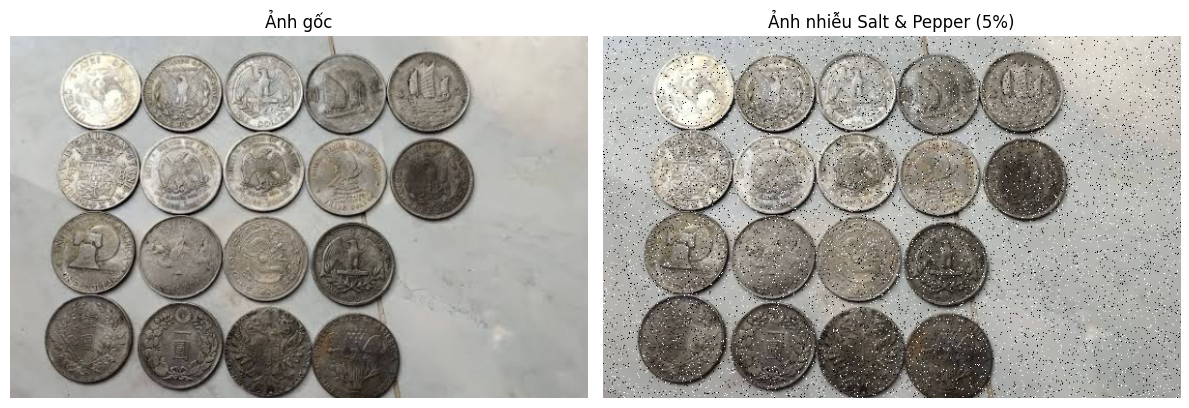

True

In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def add_salt_pepper_noise(image, amount=0.05, salt_ratio=0.5):
    """
    image: Ảnh đầu vào
    amount: Tỷ lệ pixel bị nhiễu (0.05 = 5%)
    salt_ratio: Tỷ lệ nhiễu trắng trong tổng nhiễu
    """
    noisy = image.copy()
    h, w = image.shape[:2]

    num_noise = int(amount * h * w)
    num_salt = int(num_noise * salt_ratio)
    num_pepper = num_noise - num_salt

    # Nhiễu muối: pixel trắng
    y = np.random.randint(0, h, num_salt)
    x = np.random.randint(0, w, num_salt)
    noisy[y, x] = 255

    # Nhiễu tiêu: pixel đen
    y = np.random.randint(0, h, num_pepper)
    x = np.random.randint(0, w, num_pepper)
    noisy[y, x] = 0

    return noisy


# Đọc ảnh
image = cv2.imread("xu-dinh.png")

if image is None:
    raise FileNotFoundError("Không tìm thấy ảnh thuoc.png")

# Thêm nhiễu 5%
noisy_image = add_salt_pepper_noise(image, amount=0.05)

# Chuyển BGR sang RGB để hiển thị đúng màu bằng Matplotlib
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
noisy_rgb = cv2.cvtColor(noisy_image, cv2.COLOR_BGR2RGB)

# Hiển thị ảnh
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Ảnh gốc")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(noisy_rgb)
plt.title("Ảnh nhiễu Salt & Pepper (5%)")
plt.axis("off")

plt.tight_layout()
plt.show()

# Lưu ảnh nhiễu nếu cần
cv2.imwrite("thuoc_noisy.png", noisy_image)

Ngưỡng Otsu: 175.0

Kernel:
[[0 1 0]
 [1 1 1]
 [0 1 0]]


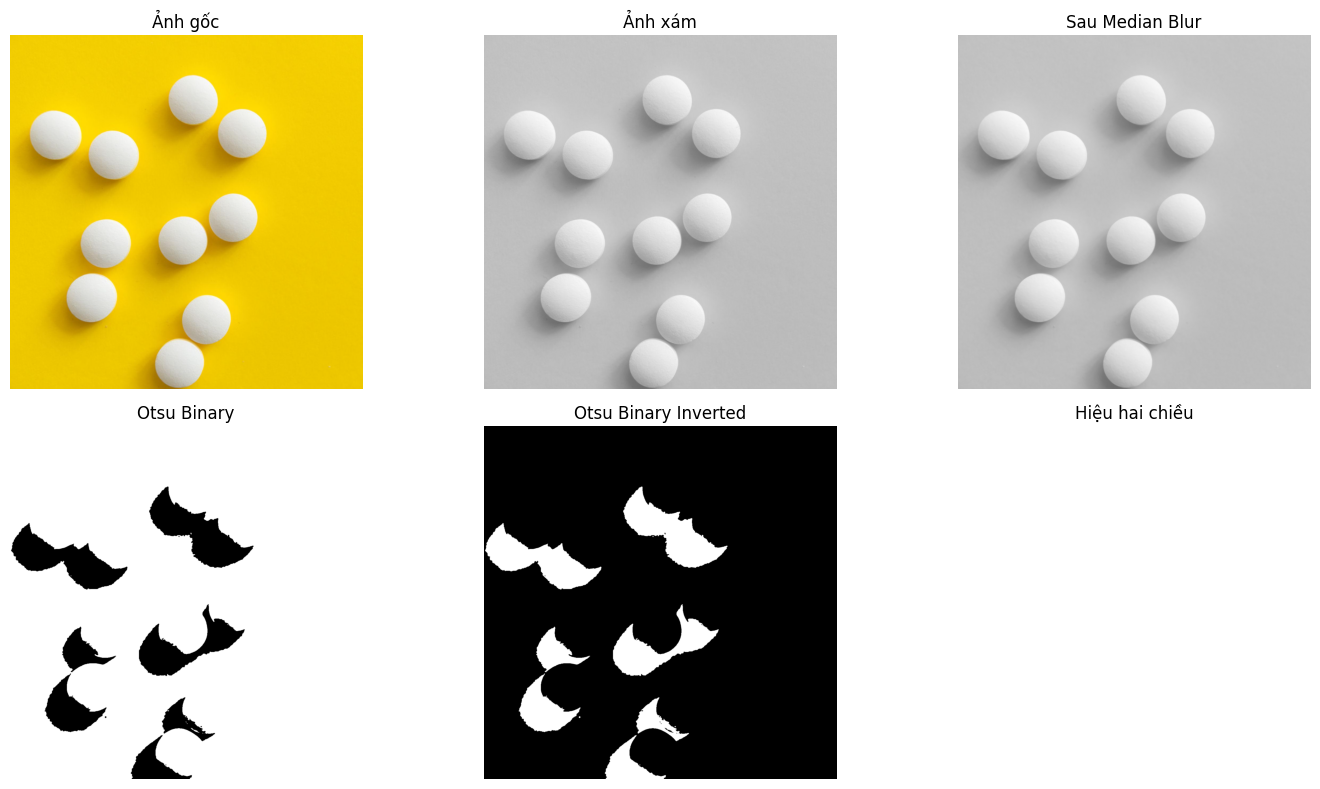


===== OTSU BINARY =====
Tỷ lệ pixel trắng: 89.3 %
Manual Erosion khớp OpenCV: True
Manual Dilation khớp OpenCV: True


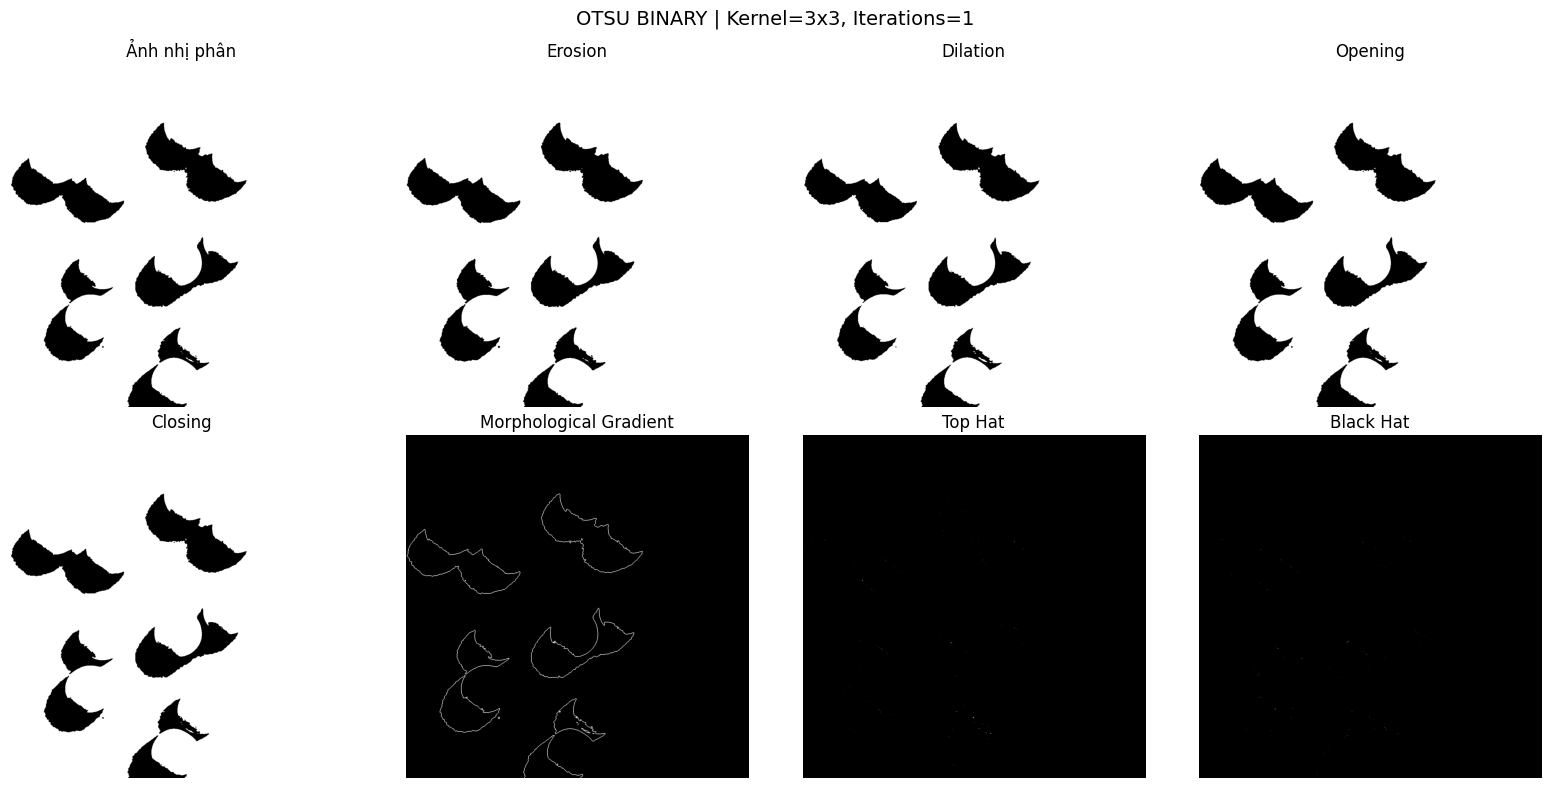

KeyboardInterrupt: 

In [40]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1. ĐỌC ẢNH
# =========================================================
IMAGE_PATH = 'keo_dinh.png'  # Đổi thành đúng tên file ảnh của bạn

img_color = cv2.imread(IMAGE_PATH)

if img_color is None:
    raise ValueError(f"Không đọc được ảnh: {IMAGE_PATH}")

gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

# Khử nhiễu muối tiêu
blur = cv2.medianBlur(gray, 5)


# =========================================================
# 2. THRESHOLD OTSU THEO HAI CHIỀU
# =========================================================
otsu_threshold, binary = cv2.threshold(
    blur, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

_, binary_inv = cv2.threshold(
    blur, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

print("Ngưỡng Otsu:", otsu_threshold)


# =========================================================
# 3. HÀM MORPHOLOGY TỰ VIẾT
# =========================================================
def manual_morphology(image, kernel, mode='erosion'):
    """
    Ảnh nhị phân: vật thể trắng 255, nền đen 0.
    Kernel chứa các phần tử hoạt động bằng 1.
    """
    if mode not in ('erosion', 'dilation'):
        raise ValueError("mode phải là erosion hoặc dilation")

    img_h, img_w = image.shape
    k_h, k_w = kernel.shape

    pad_h = k_h // 2
    pad_w = k_w // 2

    # Giá trị padding cho ảnh nhị phân
    pad_value = 255 if mode == 'erosion' else 0

    padded = np.pad(
        image,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode='constant',
        constant_values=pad_value
    )

    output = np.zeros_like(image)
    active_kernel = kernel != 0

    for y in range(img_h):
        for x in range(img_w):
            roi = padded[y:y + k_h, x:x + k_w]
            pixels = roi[active_kernel]

            if mode == 'erosion':
                if np.all(pixels == 255):
                    output[y, x] = 255
            else:
                if np.any(pixels == 255):
                    output[y, x] = 255

    return output


# =========================================================
# 4. CẤU HÌNH MORPHOLOGY
# =========================================================
KERNEL_SIZE = 3
ITERATIONS = 1

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (KERNEL_SIZE, KERNEL_SIZE)
)

print("\nKernel:")
print(kernel)


# =========================================================
# 5. KIỂM TRA CẢ HAI CHIỀU THRESHOLD
# =========================================================
def test_morphology(binary_img, label):
    results = {}

    results['Ảnh nhị phân'] = binary_img

    results['Erosion'] = cv2.erode(
        binary_img, kernel, iterations=ITERATIONS
    )

    results['Dilation'] = cv2.dilate(
        binary_img, kernel, iterations=ITERATIONS
    )

    results['Opening'] = cv2.morphologyEx(
        binary_img, cv2.MORPH_OPEN,
        kernel, iterations=ITERATIONS
    )

    results['Closing'] = cv2.morphologyEx(
        binary_img, cv2.MORPH_CLOSE,
        kernel, iterations=ITERATIONS
    )

    # Gradient = Dilation - Erosion
    results['Morphological Gradient'] = cv2.morphologyEx(
        binary_img, cv2.MORPH_GRADIENT, kernel
    )

    results['Top Hat'] = cv2.morphologyEx(
        binary_img, cv2.MORPH_TOPHAT,
        kernel, iterations=ITERATIONS
    )

    results['Black Hat'] = cv2.morphologyEx(
        binary_img, cv2.MORPH_BLACKHAT,
        kernel, iterations=ITERATIONS
    )

    # Kiểm tra hai hàm tự viết với OpenCV
    manual_ero = manual_morphology(
        binary_img, kernel, 'erosion'
    )
    manual_dil = manual_morphology(
        binary_img, kernel, 'dilation'
    )

    cv_ero = cv2.erode(binary_img, kernel)
    cv_dil = cv2.dilate(binary_img, kernel)

    print(f"\n===== {label} =====")
    print("Tỷ lệ pixel trắng:",
          round(np.mean(binary_img == 255) * 100, 2), "%")
    print("Manual Erosion khớp OpenCV:",
          np.array_equal(manual_ero, cv_ero))
    print("Manual Dilation khớp OpenCV:",
          np.array_equal(manual_dil, cv_dil))

    # Vẽ kết quả
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    fig.suptitle(
        f'{label} | Kernel={KERNEL_SIZE}x{KERNEL_SIZE}, '
        f'Iterations={ITERATIONS}',
        fontsize=14
    )

    for ax, (title, result) in zip(
        axes.flat, results.items()
    ):
        ax.imshow(result, cmap='gray', vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

    return results


# =========================================================
# 6. HIỂN THỊ CÁC BƯỚC TIỀN XỬ LÝ
# =========================================================
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

preprocess_images = [
    ('Ảnh gốc', cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)),
    ('Ảnh xám', gray),
    ('Sau Median Blur', blur),
    ('Otsu Binary', binary),
    ('Otsu Binary Inverted', binary_inv),
    ('Hiệu hai chiều', cv2.absdiff(binary, binary_inv))
]

for ax, (title, image) in zip(
    axes.flat, preprocess_images
):
    ax.imshow(
        image,
        cmap='gray' if len(image.shape) == 2 else None,
        vmin=0 if len(image.shape) == 2 else None,
        vmax=255 if len(image.shape) == 2 else None
    )
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()


# =========================================================
# 7. CHẠY MORPHOLOGY CHO CẢ HAI CHIỀU
# =========================================================
results_binary = test_morphology(
    binary, 'OTSU BINARY'
)

results_binary_inv = test_morphology(
    binary_inv, 'OTSU BINARY INVERTED'
)


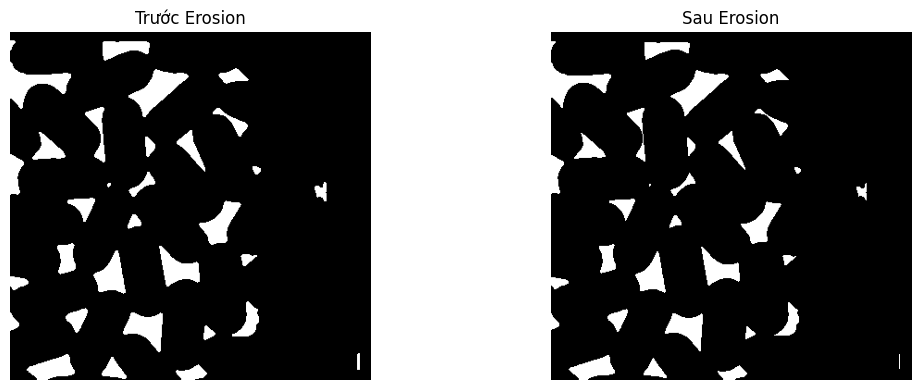

Số thành phần, tính cả nền: 33
Số thành phần vật thể: 32


In [35]:

# Đưa vật thể về trắng, nền về đen
binary_for_cc = cv2.bitwise_not(binary_inv)

# Erosion nhẹ để thử cắt các cầu nối mỏng giữa các viên thuốc
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
separated = cv2.erode(binary_for_cc, kernel, iterations=1)

# Kiểm tra kết quả
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(binary_for_cc, cmap='gray')
plt.title('Trước Erosion')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(separated, cmap='gray')
plt.title('Sau Erosion')
plt.axis('off')

plt.tight_layout()
plt.show()

# Connected Components trên ảnh sau xử lý
num_labels, labels, stats, centroids = \
    cv2.connectedComponentsWithStats(
        separated, connectivity=8
    )

print("Số thành phần, tính cả nền:", num_labels)
print("Số thành phần vật thể:", num_labels - 1)


#LẤY TỪ KHÚC NÀY (CÒN LẠI Ở TRÊN LÀ TEST THÔI)

=== KẾT QUẢ KIỂM THỬ HÀM TỰ CODE VS OPENCV ===
Erosion khớp hoàn toàn với OpenCV : False
Dilation khớp hoàn toàn với OpenCV: True


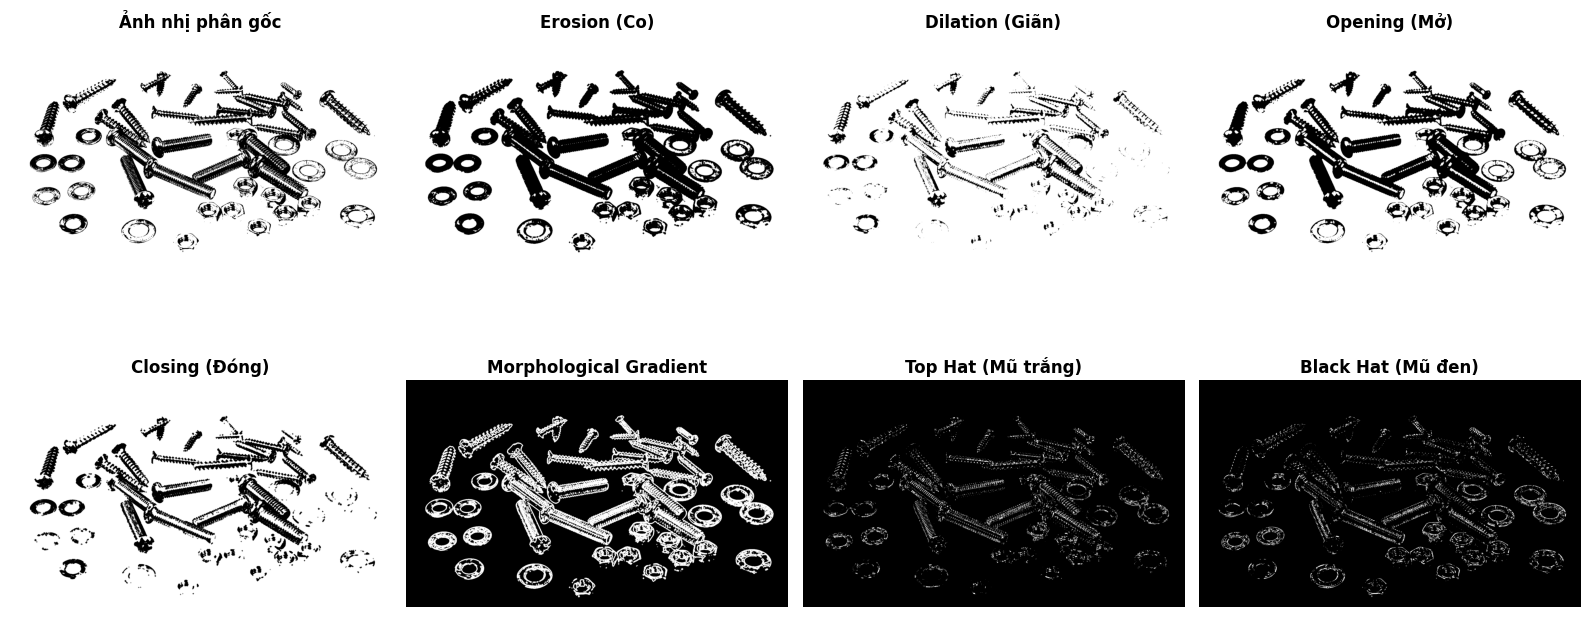

In [24]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. THUẬT TOÁN TỰ BUILD (TƯ DUY SLIDING WINDOW) - Giữ nguyên của bạn
# ---------------------------------------------------------
def manual_morphology(image, kernel, mode='erosion'):
    """
    Hàm tự code thủ công. Dùng để đối chiếu với OpenCV trong báo cáo.
    """
    img_h, img_w = image.shape
    k_h, k_w = kernel.shape
    pad_h, pad_w = k_h // 2, k_w // 2

    padded_img = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)
    output_img = np.zeros_like(image)

    for y in range(img_h):
        for x in range(img_w):
            roi = padded_img[y : y + k_h, x : x + k_w]
            pixels_under_kernel = roi[kernel == 1]

            if mode == 'erosion':
                if np.min(pixels_under_kernel) == 255:
                    output_img[y, x] = 255
            elif mode == 'dilation':
                if np.max(pixels_under_kernel) == 255:
                    output_img[y, x] = 255
    return output_img

# ---------------------------------------------------------
# 2. CÁC HÀM TIỆN ÍCH DÀNH CHO BÊN GUI GỌI
# ---------------------------------------------------------

def binarize_image(img_color, thresh_val=127, auto_otsu=True):
    """
    Chuyển ảnh sang Grayscale và Nhị phân hóa.
    Nếu auto_otsu=True thì tự động tính ngưỡng cắt tối ưu cho ảnh tối.
    """
    img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
    if auto_otsu:
        # Tự động tính ngưỡng cắt theo Otsu
        _, img_binary = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    else:
        _, img_binary = cv2.threshold(img_gray, thresh_val, 255, cv2.THRESH_BINARY)
    return img_binary


def create_kernel(shape_type='rect', ksize=3):
    """
    Hàm 2: Tạo Kernel bằng OpenCV.
    Bên GUI có thể cho người dùng chọn hình dạng (Rect, Ellipse, Cross) và kích thước (3, 5, 7, 9...)
    """
    if shape_type == 'rect':
        return cv2.getStructuringElement(cv2.MORPH_RECT, (ksize, ksize))
    elif shape_type == 'ellipse':
        return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
    elif shape_type == 'cross':
        return cv2.getStructuringElement(cv2.MORPH_CROSS, (ksize, ksize))

    # Mặc định
    return cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

def apply_morphology(binary_img, op_name, kernel, iterations=1):
    """
    Hàm 3: Áp dụng phép toán hình thái học bằng OpenCV.
    Hỗ trợ đầy đủ các phép toán như trong ảnh bạn cung cấp (opening, closing, top hat...).
    """
    if op_name == 'erosion':
        return cv2.erode(binary_img, kernel, iterations=iterations)
    elif op_name == 'dilation':
        return cv2.dilate(binary_img, kernel, iterations=iterations)
    elif op_name == 'opening':
        return cv2.morphologyEx(binary_img, cv2.MORPH_OPEN, kernel, iterations=iterations)
    elif op_name == 'closing':
        return cv2.morphologyEx(binary_img, cv2.MORPH_CLOSE, kernel, iterations=iterations)
    elif op_name == 'gradient':
        return cv2.morphologyEx(binary_img, cv2.MORPH_GRADIENT, kernel, iterations=iterations)
    elif op_name == 'top_hat':
        return cv2.morphologyEx(binary_img, cv2.MORPH_TOPHAT, kernel, iterations=iterations)
    elif op_name == 'black_hat':
        return cv2.morphologyEx(binary_img, cv2.MORPH_BLACKHAT, kernel, iterations=iterations)

    return binary_img
# ---------------------------------------------------------
# 3. KỊCH BẢN KIỂM THỬ (TEST & PRINT TOÀN BỘ KẾT QUẢ) -GUI TRUYỀN TÙY Ý (ƯU TIÊN KERNEL NHƯ MẪU)
# ---------------------------------------------------------
# Bước 3.1: Nạp ảnh
# Bạn có thể thay bằng tên file ảnh của bạn: "Dilation.png" hoặc "A1_XLY.jpg"
image_path = "vit.png"
img_color = cv2.imread(image_path)

if img_color is None:
    print(f"Không tìm thấy file '{image_path}', khởi tạo ảnh tổng hợp mẫu để test...")
    # Tạo ảnh mẫu: hình vuông trắng ở giữa nền đen, có thêm đốm nhiễu và lỗ rỗng
    img_color = np.zeros((200, 200, 3), dtype=np.uint8)
    img_color[50:150, 50:150] = 255          # Hình vuông trắng
    img_color[20:25, 20:25] = 255            # Đốm sáng ở nền (Salt noise)
    img_color[80:90, 80:90] = 0              # Lỗ thủng bên trong (Pepper/Hole)
    # Nối 2 hình nhỏ làm cầu dính (Bridge)
    img_color[60:75, 150:175] = 255

# Bước 3.2: Nhị phân hóa ảnh
img_binary = binarize_image(img_color, auto_otsu=True)

# Bước 3.3: Tạo Kernel (ví dụ chọn hình dấu thập, kích thước 3x3 hoặc 5x5)
kernel = create_kernel(shape_type='cross', ksize=7)

# Bước 3.4: Đối chiếu hàm tự viết (Manual) với OpenCV
manual_ero = manual_morphology(img_binary, kernel, mode='erosion')
manual_dil = manual_morphology(img_binary, kernel, mode='dilation')

cv2_ero = apply_morphology(img_binary, 'erosion', kernel)
cv2_dil = apply_morphology(img_binary, 'dilation', kernel)

print("=== KẾT QUẢ KIỂM THỬ HÀM TỰ CODE VS OPENCV ===")
print("Erosion khớp hoàn toàn với OpenCV :", np.array_equal(manual_ero, cv2_ero))
print("Dilation khớp hoàn toàn với OpenCV:", np.array_equal(manual_dil, cv2_dil))

# Bước 3.5: Thực thi tất cả các phép toán còn lại
operations = {
    'Ảnh nhị phân gốc': img_binary,
    'Erosion (Co)': cv2_ero,
    'Dilation (Giãn)': cv2_dil,
    'Opening (Mở)': apply_morphology(img_binary, 'opening', kernel),
    'Closing (Đóng)': apply_morphology(img_binary, 'closing', kernel),
    'Morphological Gradient': apply_morphology(img_binary, 'gradient', kernel),
    'Top Hat (Mũ trắng)': apply_morphology(img_binary, 'top_hat', kernel),
    'Black Hat (Mũ đen)': apply_morphology(img_binary, 'black_hat', kernel)
}

# ---------------------------------------------------------
# 4. HIỂN THỊ TẤT CẢ LÊN LƯỚI 2x4 (BÁM SÁT SLIDE/BÁO CÁO)
# ---------------------------------------------------------
plt.figure(figsize=(16, 8))

for idx, (title, img_result) in enumerate(operations.items(), start=1):
    plt.subplot(2, 4, idx)
    plt.imshow(img_result, cmap='gray')
    plt.title(title, fontsize=12, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

##DƯỚI ĐÂY LÀ T TEST PHẦN 2 BÂY

=== MANUAL VS OPENCV ===
Erosion khớp: True
Dilation khớp: True


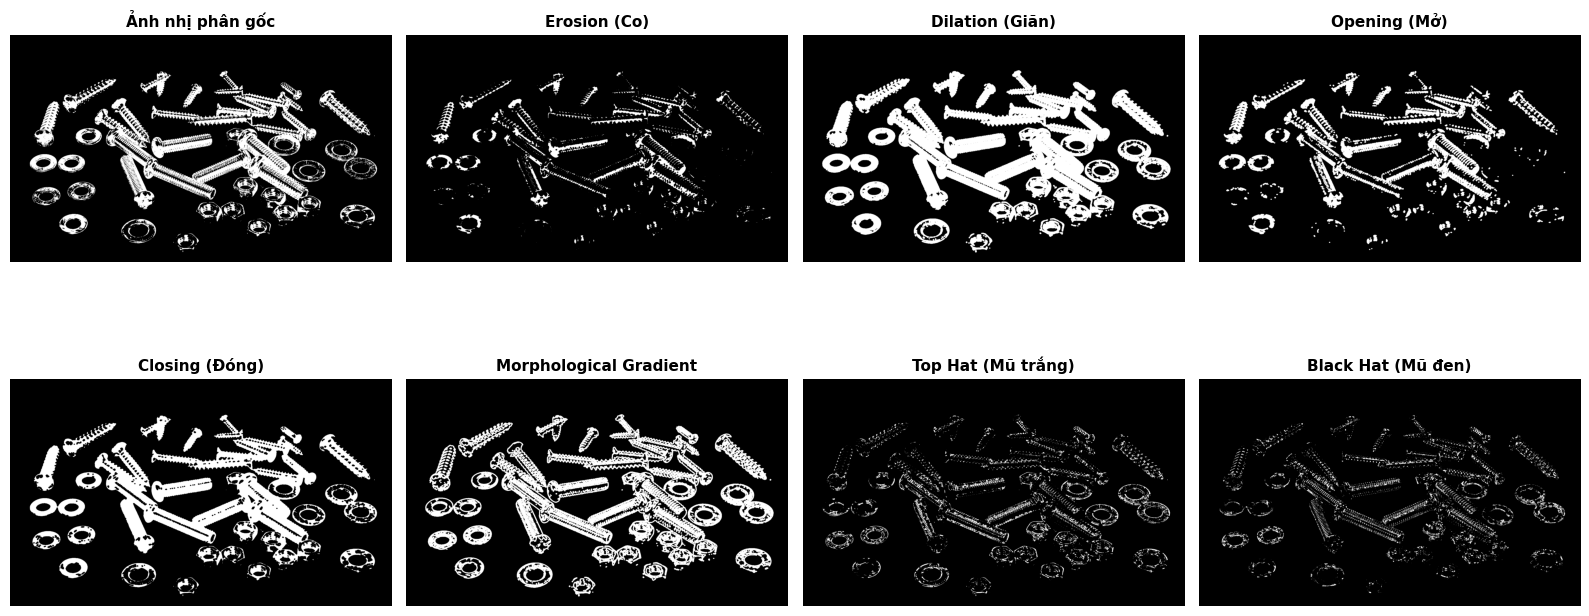

Số vùng vật thể đủ diện tích: 31


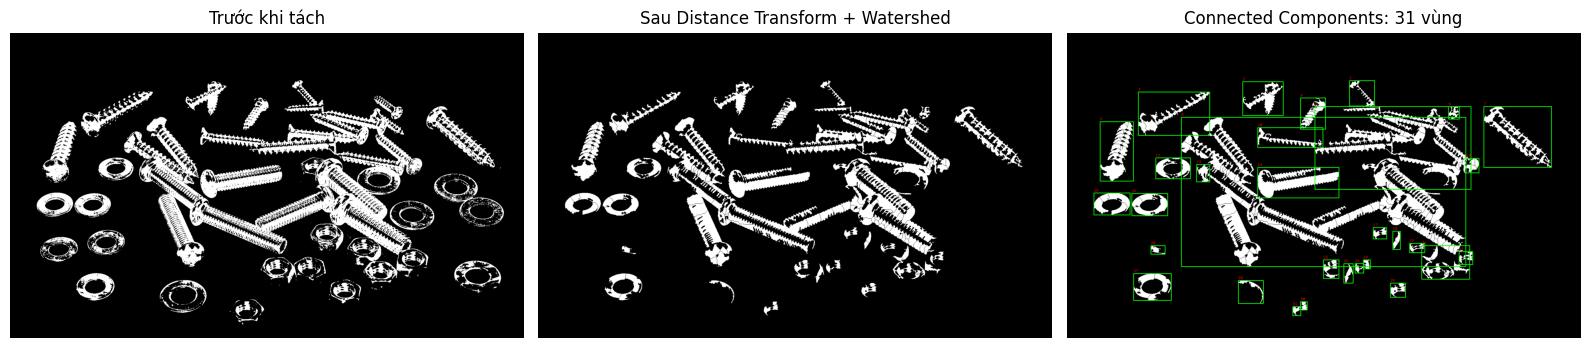

In [25]:

import numpy as np
import cv2
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. MORPHOLOGY TỰ BUILD - SLIDING WINDOW
# ---------------------------------------------------------
def manual_morphology(image, kernel, mode='erosion'):
    """
    Tự cài đặt Erosion và Dilation để đối chiếu OpenCV.
    Quy ước: vật thể trắng 255, nền đen 0.
    """
    if mode not in ('erosion', 'dilation'):
        raise ValueError("mode phải là erosion hoặc dilation")

    img_h, img_w = image.shape
    k_h, k_w = kernel.shape
    pad_h, pad_w = k_h // 2, k_w // 2

    # Erosion: padding trắng; Dilation: padding đen
    pad_value = 255 if mode == 'erosion' else 0

    padded_img = np.pad(
        image,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode='constant',
        constant_values=pad_value
    )

    output_img = np.zeros_like(image)
    active_kernel = kernel != 0

    for y in range(img_h):
        for x in range(img_w):
            roi = padded_img[y:y + k_h, x:x + k_w]
            pixels = roi[active_kernel]

            if mode == 'erosion':
                if np.all(pixels == 255):
                    output_img[y, x] = 255
            else:
                if np.any(pixels == 255):
                    output_img[y, x] = 255

    return output_img


# ---------------------------------------------------------
# 2. NHỊ PHÂN HÓA
# ---------------------------------------------------------
def binarize_image(img_color, thresh_val=127, auto_otsu=True):
    """
    Chuyển ảnh sang nhị phân.
    Tự chọn chiều để nền là đen, vật thể là trắng,
    dựa trên màu nền ở viền ảnh.
    """
    img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

    if auto_otsu:
        _, img_binary = cv2.threshold(
            img_gray, 0, 255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )
    else:
        _, img_binary = cv2.threshold(
            img_gray, thresh_val, 255, cv2.THRESH_BINARY
        )

    # Ước lượng nền từ các pixel ở mép ảnh
    border = np.concatenate([
        img_binary[0, :],
        img_binary[-1, :],
        img_binary[:, 0],
        img_binary[:, -1]
    ])

    # Nếu phần lớn viền trắng thì đảo để nền thành đen
    if np.mean(border) > 127:
        img_binary = cv2.bitwise_not(img_binary)

    return img_binary


# ---------------------------------------------------------
# 3. TẠO KERNEL
# ---------------------------------------------------------
def create_kernel(shape_type='rect', ksize=3):
    if ksize < 1:
        raise ValueError("ksize phải >= 1")

    # Đảm bảo kernel có kích thước lẻ
    if ksize % 2 == 0:
        ksize += 1

    if shape_type == 'rect':
        shape = cv2.MORPH_RECT
    elif shape_type == 'ellipse':
        shape = cv2.MORPH_ELLIPSE
    elif shape_type == 'cross':
        shape = cv2.MORPH_CROSS
    else:
        shape = cv2.MORPH_RECT

    return cv2.getStructuringElement(shape, (ksize, ksize))


# ---------------------------------------------------------
# 4. CÁC PHÉP MORPHOLOGY BẰNG OPENCV
# ---------------------------------------------------------
def apply_morphology(binary_img, op_name, kernel, iterations=1):
    if op_name == 'erosion':
        return cv2.erode(binary_img, kernel, iterations=iterations)

    elif op_name == 'dilation':
        return cv2.dilate(binary_img, kernel, iterations=iterations)

    elif op_name == 'opening':
        return cv2.morphologyEx(
            binary_img, cv2.MORPH_OPEN,
            kernel, iterations=iterations
        )

    elif op_name == 'closing':
        return cv2.morphologyEx(
            binary_img, cv2.MORPH_CLOSE,
            kernel, iterations=iterations
        )

    elif op_name == 'gradient':
        return cv2.morphologyEx(
            binary_img, cv2.MORPH_GRADIENT, kernel
        )

    elif op_name == 'top_hat':
        return cv2.morphologyEx(
            binary_img, cv2.MORPH_TOPHAT,
            kernel, iterations=iterations
        )

    elif op_name == 'black_hat':
        return cv2.morphologyEx(
            binary_img, cv2.MORPH_BLACKHAT,
            kernel, iterations=iterations
        )

    return binary_img


# ---------------------------------------------------------
# 5. TÁCH CÁC VẬT THỂ DÍNH NHAU: DISTANCE + WATERSHED
# ---------------------------------------------------------
def separate_touching_objects(binary_img, distance_ratio=0.35):
    """
    Tách các vật thể trắng đang tiếp xúc nhau.

    distance_ratio:
        Nhỏ hơn -> marker nhiều hơn, có thể tách quá mức.
        Lớn hơn -> marker ít hơn, có thể vẫn gộp vật thể.

    Trả về:
        separated_mask: mặt nạ các vật thể sau tách.
        labels: nhãn Watershed, -1 là đường biên.
    """
    # Loại bỏ đốm nhỏ và làm kín lỗ nhỏ một cách nhẹ nhàng
    kernel = create_kernel('ellipse', 3)
    cleaned = cv2.morphologyEx(
        binary_img, cv2.MORPH_OPEN, kernel, iterations=1
    )

    # Khoảng cách từ pixel trắng tới pixel nền gần nhất
    dist = cv2.distanceTransform(cleaned, cv2.DIST_L2, 5)

    if dist.max() == 0:
        return cleaned, np.zeros(cleaned.shape, dtype=np.int32)

    # Vùng lõi của từng vật thể làm marker ban đầu
    _, sure_fg = cv2.threshold(
        dist, distance_ratio * dist.max(), 255, cv2.THRESH_BINARY
    )
    sure_fg = sure_fg.astype(np.uint8)

    # Ước lượng nền chắc chắn
    sure_bg = cv2.dilate(cleaned, kernel, iterations=2)

    # Vùng chưa biết nằm giữa lõi vật thể và nền chắc chắn
    unknown = cv2.subtract(sure_bg, sure_fg)

    # Tạo nhãn marker
    num_markers, markers = cv2.connectedComponents(sure_fg)

    # Watershed cần marker nền bắt đầu từ 1;
    # vùng chưa biết được đánh dấu bằng 0
    markers = markers + 1
    markers[unknown == 255] = 0

    # Watershed nhận ảnh màu và sửa markers tại chỗ
    img_3ch = cv2.cvtColor(cleaned, cv2.COLOR_GRAY2BGR)
    markers = cv2.watershed(img_3ch, markers)

    # Mỗi vùng có nhãn > 1 là một vùng vật thể.
    # Bỏ đường biên Watershed (-1) khỏi mặt nạ.
    separated_mask = np.zeros_like(cleaned)

    for label_id in np.unique(markers):
        if label_id > 1:
            separated_mask[markers == label_id] = 255

    return separated_mask, markers


# ---------------------------------------------------------
# 6. CONNECTED COMPONENTS + HIỂN THỊ BOUNDING BOX
# ---------------------------------------------------------
def analyze_components(binary_img, min_area=30):
    num_labels, labels, stats, centroids = \
        cv2.connectedComponentsWithStats(
            binary_img, connectivity=8
        )

    output = cv2.cvtColor(binary_img, cv2.COLOR_GRAY2BGR)
    count = 0

    for i in range(1, num_labels):
        x, y, w, h, area = stats[i]

        # Bỏ các thành phần quá nhỏ
        if area < min_area:
            continue

        count += 1

        cv2.rectangle(
            output, (x, y), (x + w, y + h),
            (0, 255, 0), 2
        )

        cv2.putText(
            output, str(count), (x, max(y - 5, 12)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5,
            (0, 0, 255), 1
        )

    print("Số vùng vật thể đủ diện tích:", count)

    return output, count, labels, stats, centroids


# ---------------------------------------------------------
# 7. ĐỌC ẢNH
# ---------------------------------------------------------
image_path = "vit.png"
img_color = cv2.imread(image_path)

if img_color is None:
    raise FileNotFoundError(
        f"Không tìm thấy file '{image_path}'. "
        "Hãy kiểm tra tên và đường dẫn ảnh."
    )

# Nhị phân hóa: vật thể trắng, nền đen
img_binary = binarize_image(img_color, auto_otsu=True)

# Kernel và số lần lặp cho các phép morphology
kernel = create_kernel(shape_type='ellipse', ksize=7)
iterations = 1


# ---------------------------------------------------------
# 8. KIỂM TRA MANUAL VS OPENCV
# ---------------------------------------------------------
manual_ero = manual_morphology(
    img_binary, kernel, mode='erosion'
)
manual_dil = manual_morphology(
    img_binary, kernel, mode='dilation'
)

cv2_ero = apply_morphology(img_binary, 'erosion', kernel)
cv2_dil = apply_morphology(img_binary, 'dilation', kernel)

print("=== MANUAL VS OPENCV ===")
print(
    "Erosion khớp:",
    np.array_equal(manual_ero, cv2_ero)
)
print(
    "Dilation khớp:",
    np.array_equal(manual_dil, cv2_dil)
)


# ---------------------------------------------------------
# 9. GIỮ LƯỚI 2x4 CÁC PHÉP MORPHOLOGY CỦA BẠN
# ---------------------------------------------------------
operations = {
    'Ảnh nhị phân gốc': img_binary,
    'Erosion (Co)': cv2_ero,
    'Dilation (Giãn)': cv2_dil,
    'Opening (Mở)': apply_morphology(
        img_binary, 'opening', kernel, iterations
    ),
    'Closing (Đóng)': apply_morphology(
        img_binary, 'closing', kernel, iterations
    ),
    'Morphological Gradient': apply_morphology(
        img_binary, 'gradient', kernel
    ),
    'Top Hat (Mũ trắng)': apply_morphology(
        img_binary, 'top_hat', kernel, iterations
    ),
    'Black Hat (Mũ đen)': apply_morphology(
        img_binary, 'black_hat', kernel, iterations
    )
}

plt.figure(figsize=(16, 8))

for idx, (title, img_result) in enumerate(
    operations.items(), start=1
):
    plt.subplot(2, 4, idx)
    plt.imshow(img_result, cmap='gray', vmin=0, vmax=255)
    plt.title(title, fontsize=11, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 10. WATERSHED VÀ CONNECTED COMPONENTS
# ---------------------------------------------------------
separated, watershed_labels = separate_touching_objects(
    img_binary,
    distance_ratio=0.35
)

boxed, count, labels, stats, centroids = analyze_components(
    separated,
    min_area=30
)

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_binary, cmap='gray')
plt.title('Trước khi tách')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(separated, cmap='gray')
plt.title('Sau Distance Transform + Watershed')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(boxed, cv2.COLOR_BGR2RGB))
plt.title(f'Connected Components: {count} vùng')
plt.axis('off')

plt.tight_layout()
plt.show()


Số vùng Watershed đủ diện tích: 251


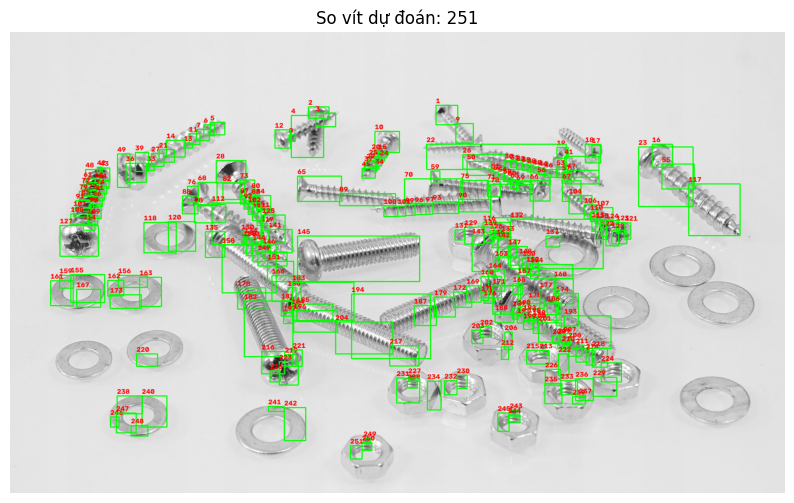

In [26]:
def count_screws_from_watershed(
    img_color, watershed_labels, min_area=30
):
    output = img_color.copy()
    count = 0

    for label_id in np.unique(watershed_labels):
        # -1: đường biên; 1: vùng nền
        if label_id <= 1:
            continue

        region = (watershed_labels == label_id)
        area = np.count_nonzero(region)

        # Loại các vùng quá nhỏ
        if area < min_area:
            continue

        ys, xs = np.where(region)

        x1, x2 = xs.min(), xs.max()
        y1, y2 = ys.min(), ys.max()

        count += 1

        # Vẽ khung và số thứ tự
        cv2.rectangle(
            output, (x1, y1), (x2, y2),
            (0, 255, 0), 2
        )

        cv2.putText(
            output, str(count),
            (x1, max(y1 - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6, (0, 0, 255), 2
        )

    print("Số vùng Watershed đủ diện tích:", count)

    return output, count
# Đếm trực tiếp các vùng Watershed
boxed_watershed, screw_count = count_screws_from_watershed(
    img_color,
    watershed_labels,
    min_area=30
)

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(boxed_watershed, cv2.COLOR_BGR2RGB))
plt.title(f"So vít dự đoán: {screw_count}")
plt.axis("off")
plt.show()